# Data-Driven Bank Marketing: Term Deposit Subscription Prediction and Campaign Prioritization

**Created By Rika Fadhilah Naufal and Yonkie Yudha Ardika**

## 1. Business Understanding

### 1.1 Business Context

Industri perbankan menyediakan berbagai produk keuangan, salah satunya term deposit, yaitu simpanan berjangka yang ditawarkan kepada nasabah untuk periode tertentu.

Project ini menggunakan historical direct marketing campaign dari sebuah institusi perbankan di Portugal, di mana client dihubungi melalui phone call untuk menawarkan term deposit.

Namun, tidak semua client memberikan respons yang sama. Dari 41,188 historical campaign observations, hanya 4,640 (11.27%) yang menghasilkan subscription, sedangkan 36,548 (88.73%) tidak menghasilkan subscription.

Oleh karena itu, project ini menggunakan dua pendekatan:

1. **Data Analytics** — memahami karakteristik client dan kondisi campaign yang berkaitan dengan subscription.
2. **Machine Learning** — menghasilkan prediction score untuk membantu menentukan client priority dalam campaign.

#### Stakeholders

| Stakeholder | Peran |
|---|---|
| **Marketing / Campaign Manager** | Primary stakeholder; menentukan target dan prioritas campaign |
| **CRM Team** | Mengelola customer profile dan historical interaction |
| **Term Deposit Product Manager** | Memantau product performance dan target segment |
| **Campaign Operations / Contact Center** | Menjalankan outbound campaign berdasarkan prioritas |


### 1.2 Problem Statement

#### 1.2.1 Analytics Problem Statement

> **Client seperti apa dan kondisi campaign seperti apa yang memiliki tingkat subscription lebih tinggi sehingga Marketing / Campaign Manager dapat menentukan prioritas campaign dengan lebih terarah?**

Analisis mempertimbangkan **client profile, campaign history, contact pattern, dan economic conditions** serta hubungannya dengan subscription outcome.

#### 1.2.2 Machine Learning Problem Statement

> **Bagaimana memprediksi kemungkinan seorang client melakukan subscription terhadap term deposit sehingga Marketing / Campaign Manager dapat memprioritaskan client yang lebih potensial dalam direct marketing campaign?**

| Aspect | Definition |
|---|---|
| **What** | Memprediksi kemungkinan subscription terhadap term deposit |
| **Who** | Client yang eligible dalam active term-deposit campaign |
| **When** | Selama campaign execution, sebelum contact attempt dilakukan |
| **Why** | Membantu menentukan client yang lebih potensial |
| **Output** | Prediction score untuk client ranking dan campaign prioritization |


### 1.3 Project Goals

| Perspective | Goal |
|---|---|
| **Business** | Membantu Marketing / Campaign Manager menentukan prioritas client secara lebih terarah berdasarkan data historis |
| **Analytics** | Mengidentifikasi client characteristics dan campaign conditions yang berkaitan dengan subscription |
| **Machine Learning** | Membangun classification model untuk menghasilkan prediction score sebagai dasar client ranking dan campaign prioritization |


### 1.4 Business Value

Hasil analytics dan prediction model diharapkan dapat membantu bank:

- memprioritaskan client berdasarkan data dan **prediction score**;
- membuat direct marketing campaign lebih terarah;
- mengurangi campaign effort pada client dengan **prediction score yang lebih rendah**;
- mengevaluasi potential campaign-cost difference melalui scenario analysis.

Dataset tidak menyediakan actual contact cost, revenue per subscription, atau customer value. Oleh karena itu, project tidak menghitung actual profit atau ROI. External contact-cost benchmark hanya digunakan sebagai illustrative business scenario.

### 1.5 Campaign Cost Assumption

Dataset tidak menyediakan actual campaign cost. Untuk memberikan ilustrasi business impact, digunakan external benchmark dari ContactBabel's US Contact Center Decision-Makers' Guide 2009/2010 (https://www.contactbabel.com/wp-content/uploads/2017/08/The-US-Contact-Center-Decision-Makers-Guide-2009-2010-v2.pdf)

Laporan tersebut mencatat median cost sekitar USD 5.00 per outbound sales call yang berhasil terhubung dengan intended recipient, dengan mean sebesar USD 9.10.

Karena benchmark berasal dari contact center di Amerika Serikat dan bukan dari bank pada dataset ini, nilai tersebut digunakan hanya sebagai **scenario assumption**, bukan sebagai actual campaign cost.

Dalam business simulation, diasumsikan setiap prioritized client pada evaluated scoring cycle menghasilkan satu **benchmark-equivalent outbound contact**. **USD 5.00 per contact** digunakan sebagai base scenario, sedangkan **USD 9.10 per contact** digunakan sebagai sensitivity scenario.

### 1.6 Machine Learning Error Analysis

Project merupakan **binary classification problem** dengan:

> **Positive class: `y = yes` — client melakukan subscription terhadap term deposit.**

| Outcome | Business Interpretation |
|---|---|
| **True Positive (TP)** | Client diprioritaskan dan melakukan subscription |
| **False Positive (FP)** | Client diprioritaskan tetapi tidak melakukan subscription |
| **False Negative (FN)** | Client tidak diprioritaskan padahal melakukan subscription |
| **True Negative (TN)** | Client tidak diprioritaskan dan tidak melakukan subscription |

#### Business Consequence

- **False Positive (FP)** — campaign effort dialokasikan kepada client yang tidak menghasilkan subscription. Jika setiap prioritized client menghasilkan satu benchmark-equivalent outbound contact, FP juga merepresentasikan potential unnecessary contact cost.
- **False Negative (FN)** — potential subscriber tidak memperoleh prioritas campaign, sehingga bank berpotensi kehilangan subscription opportunity.

Dalam business context project ini, **False Negative perlu mendapat perhatian khusus** karena merepresentasikan actual subscriber yang tidak masuk ke prioritized campaign list.

Namun, mengurangi FN secara agresif dengan menurunkan classification threshold dapat meningkatkan FP dan jumlah client yang harus dihubungi.

Karena itu, model tidak dievaluasi hanya berdasarkan satu jenis error. Trade-off dievaluasi melalui:

- **Recall** untuk mengukur coverage terhadap actual subscribers;
- **Precision** untuk mengukur efficiency dari prioritized clients;
- **Confusion Matrix** untuk melihat jumlah TP, FP, FN, dan TN secara langsung;
- **Targeted Rate** untuk mengukur besarnya campaign population yang perlu ditindaklanjuti.

External contact-cost benchmark digunakan untuk memberikan illustrative cost terhadap FP setelah final model evaluation.

Dataset tidak menyediakan revenue per subscription, deposit value, atau customer profitability. Karena itu, financial impact FN tidak dikonversi menjadi monetary value.

### 1.7 Evaluation Metric Strategy

Target memiliki class imbalance dengan positive class hanya sekitar **11.27%**, sehingga **Accuracy tidak digunakan sebagai primary model-selection metric**.

Metric strategy dibedakan menjadi dua level:

1. **Model-selection metric** — digunakan untuk memilih model dengan ranking performance terbaik.
2. **Operating metrics** — digunakan untuk mengevaluasi trade-off ketika model digunakan untuk campaign prioritization.

#### Primary Model-Selection Metric — Average Precision (AP)

**Average Precision (AP)** digunakan sebagai primary model-selection metric.

AP merangkum Precision–Recall performance pada berbagai classification thresholds dan berfokus pada kemampuan model dalam melakukan ranking terhadap positive class.

Metric ini sesuai dengan project karena:

- positive class hanya sekitar **11.27%**;
- business membutuhkan ranking client berdasarkan prediction score;
- model perlu mempertahankan trade-off antara Precision dan Recall pada berbagai operating thresholds.

#### Business Operating Priority

Setelah model dipilih, **Recall diprioritaskan sebagai subscriber coverage metric**, karena False Negative merepresentasikan actual subscriber yang tidak memperoleh campaign priority.

Namun, Recall tidak digunakan secara standalone. Precision dan Targeted Rate tetap digunakan sebagai **efficiency and operational guardrails**.

#### Precision and Recall from Confusion Matrix

Secara confusion matrix:

- **Precision = TP / (TP + FP)** — dari seluruh prioritized clients, mengukur proporsi yang benar-benar melakukan subscription.
- **Recall = TP / (TP + FN)** — dari seluruh actual subscribers, mengukur proporsi yang berhasil diprioritaskan.

Dalam business context project ini:

- **Precision** merepresentasikan **targeting efficiency**;
- **Recall** merepresentasikan **subscriber coverage**.

| Decision Level | Metric | Purpose |
|---|---|---|
| **Model Selection** | **Average Precision (AP)** | Mengevaluasi ranking quality pada positive class di berbagai thresholds |
| **Subscriber Coverage** | **Recall** | Mengukur proporsi actual subscribers yang berhasil diprioritaskan |
| **Campaign Efficiency** | **Precision** | Mengukur proporsi prioritized clients yang benar-benar subscribe |
| **Balance** | **F1-score** | Menilai balance antara Precision dan Recall |
| **Overall Ranking** | **ROC-AUC** | Mengukur ranking capability terhadap kedua classes |
| **Operational Capacity** | **Targeted Rate** | Mengukur proporsi clients yang perlu dihubungi |
| **Error Analysis** | **Confusion Matrix** | Menunjukkan TP, FP, FN, dan TN secara langsung |
| **Supplementary Metric** | **Accuracy** | Memberikan overall classification accuracy tetapi bukan primary metric |

#### Threshold Strategy

Classification threshold **0.50 tidak otomatis dianggap optimal**.

Setelah model dipilih, threshold dianalisis berdasarkan trade-off antara:

- **Recall** — subscriber coverage;
- **Precision** — targeting efficiency;
- **False Positive dan False Negative**;
- **Targeted Rate** — campaign workload;
- **illustrative FP contact cost** berdasarkan external benchmark.

Karena dataset tidak menyediakan actual campaign capacity, revenue per subscription, atau customer profitability, project tidak menetapkan financially optimal threshold.

Threshold digunakan sebagai **operating scenario**, bukan universal optimum.

## 2. Data Understanding

Dataset Source: https://www.kaggle.com/datasets/volodymyrgavrysh/bank-marketing-campaigns-dataset

### 2.1 Dataset Overview & Unit of Analysis

Dataset yang digunakan adalah **Bank Marketing Campaign Dataset** dengan:

- **41,188 observations**
- **21 columns**
- **20 candidate features**
- **1 target (`y`)**

Target `y` menunjukkan apakah client melakukan subscription terhadap term deposit:

- `yes` = subscription
- `no` = tidak subscription

Satu row merepresentasikan **satu client observation dalam konteks direct marketing campaign**.

Dataset tidak memiliki **unique client identifier**, sehingga satu row tidak dapat langsung diasumsikan sebagai satu unique customer.

In [51]:
# Libraries

import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

In [52]:
df = pd.read_csv(
    "bank-additional-full.csv",
    sep=";"
)

print(f"Dataset shape: {df.shape}")
display(df.head())

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [53]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

### 2.2 Feature & Target Overview

Dataset memiliki **20 candidate features** dan **1 target (`y`)**.

#### Target

`y` merepresentasikan outcome subscription terhadap term deposit:

- `yes` = client melakukan subscription
- `no` = client tidak melakukan subscription

Positive class pada project ini adalah **`y = yes`**.

#### Feature Groups

| Feature Group | Features |
|---|---|
| **Client Profile** | `age`, `job`, `marital`, `education` |
| **Financial Profile** | `default`, `housing`, `loan` |
| **Campaign Information** | `contact`, `month`, `day_of_week`, `duration`, `campaign` |
| **Previous Campaign History** | `pdays`, `previous`, `poutcome` |
| **Economic Indicators** | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` |

#### Attribute Reference

| Feature | Type | Description |
|---|---|---|
| `age` | Numerical | Usia client |
| `job` | Categorical | Jenis pekerjaan |
| `marital` | Categorical | Status pernikahan |
| `education` | Categorical | Tingkat pendidikan |
| `default` | Categorical | Status credit default |
| `housing` | Categorical | Status housing loan |
| `loan` | Categorical | Status personal loan |
| `contact` | Categorical | Jenis communication channel |
| `month` | Categorical | Bulan last contact |
| `day_of_week` | Categorical | Hari last contact |
| `duration` | Numerical | Durasi last contact dalam detik |
| `campaign` | Numerical | Jumlah contact pada current campaign |
| `pdays` | Numerical | Hari sejak previous campaign contact |
| `previous` | Numerical | Jumlah contact sebelum current campaign |
| `poutcome` | Categorical | Outcome previous campaign |
| `emp.var.rate` | Numerical | Employment variation rate |
| `cons.price.idx` | Numerical | Consumer price index |
| `cons.conf.idx` | Numerical | Consumer confidence index |
| `euribor3m` | Numerical | Euribor 3-month rate |
| `nr.employed` | Numerical | Number of employees indicator |
| `y` | Categorical | Term deposit subscription outcome |


### 2.3 Data Quality Assessment

Data quality diperiksa melalui **actual missing value, semantic missing, duplicate, dan special value**.

| Data Quality Issue | Finding | Decision |
|---|---|---|
| **Actual Missing (`NaN`)** | Tidak ditemukan actual missing value | Tidak memerlukan imputation |
| **Semantic Missing — `unknown`** | Terdapat pada `job`, `marital`, `education`, `default`, `housing`, dan `loan`; sebanyak **10,700 observations (25.98%)** memiliki minimal satu `unknown` | Dipertahankan sebagai kategori tersendiri dan dievaluasi lebih lanjut |
| **Exact Duplicate** | Terdapat **12 exact duplicate rows** | Tidak auto-drop karena tidak tersedia unique client identifier |
| **`pdays = 999`** | **39,673 observations (96.32%)**; menunjukkan client belum pernah dihubungi pada previous campaign | Dipertahankan sebagai business-specific value dan ditangani secara khusus pada preprocessing |
| **`poutcome = nonexistent`** | **35,563 observations (86.34%)**; menunjukkan tidak adanya previous campaign outcome | Dipertahankan sebagai valid structural category |
| **`default = yes`** | Hanya **3 observations** | Dipertahankan, tetapi perlu diperhatikan sebagai very rare category |

Nilai `unknown`, `999`, dan `nonexistent` tidak langsung diperlakukan sebagai ordinary missing value karena memiliki konteks data yang perlu dipertahankan.

Detail distribusi `unknown`:

| Feature | Count | Percentage |
|---|---:|---:|
| `job` | 330 | 0.80% |
| `marital` | 80 | 0.19% |
| `education` | 1,731 | 4.20% |
| `default` | 8,597 | 20.87% |
| `housing` | 990 | 2.40% |
| `loan` | 990 | 2.40% |

In [54]:
# Actual missing
total_missing = df.isna().sum().sum()

print("Total actual missing values:", total_missing)

# Exact duplicate
print("Exact duplicate rows:", df.duplicated().sum())

# Semantic missing
unknown_summary = []

for col in df.select_dtypes(include="object").columns:
    unknown_count = (df[col] == "unknown").sum()

    if unknown_count > 0:
        unknown_summary.append({
            "Feature": col,
            "Count": unknown_count,
            "Percentage (%)":
                unknown_count / len(df) * 100
        })

unknown_df = pd.DataFrame(
    unknown_summary
)

display(
    unknown_df.round(2)
)

# Rows with at least one semantic missing value ("unknown")

unknown_cols = [
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan"
]

has_unknown = (
    df[unknown_cols]
    .eq("unknown")
    .any(axis=1)
)

unknown_row_count = has_unknown.sum()
unknown_row_pct = has_unknown.mean() * 100

print(
    f"Rows with at least one 'unknown': "
    f"{unknown_row_count:,} "
    f"({unknown_row_pct:.2f}%)"
)

# Special values
print(
    "pdays = 999:",
    (df["pdays"] == 999).sum()
)

print(
    "poutcome = nonexistent:",
    (df["poutcome"] == "nonexistent").sum()
)

print(
    "default = yes:",
    (df["default"] == "yes").sum()
)

Total actual missing values: 0
Exact duplicate rows: 12


,Feature,Count,Percentage (%)
0,job,330,0.80
1,marital,80,0.19
2,education,1731,4.20
3,default,8597,20.87
4,housing,990,2.40
5,loan,990,2.40


Rows with at least one 'unknown': 10,700 (25.98%)
pdays = 999: 39673
poutcome = nonexistent: 35563
default = yes: 3


### 2.4 Feature Availability & Leakage

Mengacu pada business use case di Section 1.2, scoring dilakukan **selama campaign execution, sebelum contact attempt dilakukan**. Feature availability dievaluasi berdasarkan decision point tersebut.

| Feature / Feature Group | Availability at Scoring Time | Decision |
|---|---|---|
| Client & financial profile | Available | Retain |
| Previous campaign history | Available | Retain |
| Economic indicators | Available sesuai scoring period | Retain |
| `contact` | Available jika communication channel telah ditentukan | Retain under defined scoring assumption |
| `month` | Available dari current campaign period | Retain |
| `day_of_week` | Available jika contact schedule telah ditentukan | Retain under defined scoring assumption |
| `campaign` | Available sebagai current campaign contact context | Retain under defined scoring assumption |
| **`duration`** | **Not available before contact selesai** | **Exclude dari pre-contact prediction model** |

#### Leakage Decision

`duration` merepresentasikan durasi contact dan baru diketahui setelah interaction berlangsung. Karena itu, feature ini dikategorikan sebagai **post-contact leakage** untuk use case campaign prioritization.

Keputusan modeling:

- `duration` **tidak digunakan pada pre-contact prediction model**;
- `duration` tetap dapat digunakan pada EDA sebagai leakage diagnostic;
- feature yang bergantung pada campaign execution context hanya digunakan berdasarkan **defined scoring assumption**.

Dengan demikian, feature selection mempertimbangkan tidak hanya predictive strength, tetapi juga **availability pada saat prediction dilakukan**.

### 2.5 EDA Focus

EDA digunakan untuk memahami pola yang berkaitan dengan subscription dan mendukung keputusan preprocessing, modeling, serta business interpretation.

Analisis difokuskan pada lima area utama:

| EDA Focus | Key Variables | Objective |
|---|---|---|
| **Target Distribution** | `y` | Memahami subscription rate dan class imbalance |
| **Client & Financial Profile** | `age`, `job`, `marital`, `education`, `default`, `housing`, `loan` | Mengidentifikasi perbedaan historical subscription rate antar client segments |
| **Campaign Context & Contact Intensity** | `contact`, `month`, `day_of_week`, `campaign` | Memahami hubungan channel, timing, dan contact frequency dengan subscription |
| **Previous Campaign History** | `pdays`, `previous`, `poutcome` | Mengevaluasi apakah historical campaign response memberikan signal terhadap subscription |
| **Economic Context & Feature Relationships** | `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Memahami association dengan target dan hubungan antar numerical features |

`duration` dianalisis hanya sebagai **leakage diagnostic** dan tidak digunakan sebagai pre-contact modeling feature.

Kategori `unknown` juga dievaluasi selama EDA untuk memastikan apakah memiliki pola target yang berbeda sebelum preprocessing decision dilakukan.

Setiap analytical finding diinterpretasikan sebagai **associational evidence**, bukan causal relationship.

## 3. Exploratory Data Analysis





### 3.1 Target Distribution

Target `y` menunjukkan apakah client melakukan subscription terhadap term deposit.

| Target | Count | Percentage |
|---|---:|---:|
| `no` | 36,548 | 88.73% |
| `yes` | 4,640 | 11.27% |

Positive class hanya mencakup **11.27%** observations, dengan imbalance ratio sekitar **7.88 : 1** antara class `no` dan `yes`.

#### Interpretation

Distribusi tersebut menunjukkan **class imbalance yang cukup kuat**, sehingga evaluasi model perlu memberikan perhatian khusus pada kemampuan mendeteksi positive class.

Dari sisi business, rendahnya historical subscription rate mendukung kebutuhan untuk melakukan **campaign prioritization** dibanding memberikan prioritas yang sama kepada seluruh client.

In [55]:
target_summary = (
    df["y"]
    .value_counts()
    .rename_axis("target")
    .reset_index(name="count")
)

target_summary["percentage"] = (
    target_summary["count"] / len(df) * 100
)

display(
    target_summary.round(2)
)

imbalance_ratio = (
    df["y"].value_counts()["no"] /
    df["y"].value_counts()["yes"]
)

print(
    f"Imbalance ratio: {imbalance_ratio:.2f}:1"
)

,target,count,percentage
0,no,36548,88.73
1,yes,4640,11.27


Imbalance ratio: 7.88:1


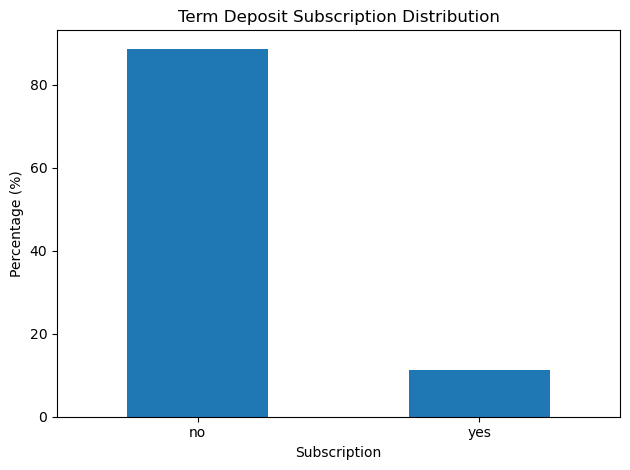

In [56]:
target_pct = (
    df["y"]
    .value_counts(normalize=True)
    .mul(100)
)

target_pct.plot(
    kind="bar"
)

plt.title(
    "Term Deposit Subscription Distribution"
)
plt.xlabel(
    "Subscription"
)
plt.ylabel(
    "Percentage (%)"
)
plt.xticks(
    rotation=0
)
plt.tight_layout()
plt.show()

### 3.2 Feature Distribution

Univariate analysis digunakan untuk memahami karakteristik numerical dan categorical features sebelum mengevaluasi hubungannya dengan target.

#### Numerical Features

| Feature | Median | Min | Max | Skewness | Key Pattern |
|---|---:|---:|---:|---:|---|
| `age` | 38 | 17 | 98 | 0.78 | Moderately right-skewed |
| `duration` | 180 | 0 | 4,918 | 3.26 | Strongly right-skewed; leakage diagnostic only |
| `campaign` | 2 | 1 | 56 | 4.76 | Strongly right-skewed |
| `pdays` | 999 | 0 | 999 | -4.92 | Dominated by special value `999` |
| `previous` | 0 | 0 | 7 | 3.83 | Strongly right-skewed / zero-heavy |
| `emp.var.rate` | 1.1 | -3.4 | 1.4 | -0.72 | Moderately left-skewed |
| `cons.price.idx` | 93.75 | 92.20 | 94.77 | -0.23 | Relatively symmetric |
| `cons.conf.idx` | -41.8 | -50.8 | -26.9 | 0.30 | Relatively symmetric |
| `euribor3m` | 4.86 | 0.63 | 5.04 | -0.71 | Moderately left-skewed |
| `nr.employed` | 5,191.0 | 4,963.6 | 5,228.1 | -1.04 | Left-skewed |

Key observations:

- `duration`, `campaign`, dan `previous` menunjukkan strong skewness.
- `pdays` tidak merepresentasikan continuous numerical distribution biasa karena **96.32% observations memiliki nilai `999`**.
- `age` menunjukkan moderate right skew, tetapi nilai usia tinggi tidak otomatis dianggap invalid.
- Economic indicators memiliki range yang relatif terbatas dan mencerminkan kondisi pada campaign period tertentu.
- `duration` hanya digunakan untuk exploratory leakage diagnostic dan tidak digunakan pada pre-contact prediction model.


#### Categorical Features

| Feature | Cardinality | Dominant Category | Share |
|---|---:|---|---:|
| `job` | 12 | `admin.` | 25.30% |
| `marital` | 4 | `married` | 60.52% |
| `education` | 8 | `university.degree` | 29.54% |
| `default` | 3 | `no` | 79.12% |
| `housing` | 3 | `yes` | 52.38% |
| `loan` | 3 | `no` | 82.43% |
| `contact` | 2 | `cellular` | 63.47% |
| `month` | 10 | `may` | 33.43% |
| `day_of_week` | 5 | `thu` | 20.94% |
| `poutcome` | 3 | `nonexistent` | 86.34% |

Key observations:

- `job`, `education`, dan `month` memiliki cardinality lebih tinggi dibanding categorical features lainnya.
- `default` sangat tidak seimbang; category `yes` hanya memiliki **3 observations**.
- `poutcome` didominasi oleh `nonexistent`, konsisten dengan banyak observations tanpa previous campaign outcome.
- Beberapa features mengandung `unknown`; category tersebut tetap dipertahankan sampai hubungannya dengan target dievaluasi.
- Distribusi `month` tidak merata, sehingga temporal pattern perlu diinterpretasikan bersama campaign context.

In [57]:
numerical_cols = df.select_dtypes(
    include="number"
).columns

numerical_summary = (
    df[numerical_cols]
    .describe()
    .T
)

numerical_summary["skewness"] = (
    df[numerical_cols]
    .skew()
)

display(
    numerical_summary[
        [
            "50%",
            "min",
            "max",
            "skewness"
        ]
    ].round(2)
)

,50%,min,max,skewness
age,38.00,17.00,98.00,0.78
duration,180.00,0.00,4918.00,3.26
campaign,2.00,1.00,56.00,4.76
pdays,999.00,0.00,999.00,-4.92
previous,0.00,0.00,7.00,3.83
emp.var.rate,1.10,-3.40,1.40,-0.72
cons.price.idx,93.75,92.20,94.77,-0.23
cons.conf.idx,-41.80,-50.80,-26.90,0.30
euribor3m,4.86,0.63,5.04,-0.71
nr.employed,5191.00,4963.60,5228.10,-1.04


In [58]:
#Visualisasi
#import matplotlib.pyplot as plt

categorical_cols = (
    df
    .select_dtypes(include="object")
    .columns
    .drop("y")
)

categorical_summary = []

for col in categorical_cols:
    counts = df[col].value_counts()

    categorical_summary.append({
        "Feature": col,
        "Cardinality": df[col].nunique(),
        "Dominant Category": counts.index[0],
        "Dominant Share (%)":
            counts.iloc[0] / len(df) * 100
    })

categorical_summary = pd.DataFrame(
    categorical_summary
)

display(
    categorical_summary.round(2)
)

,Feature,Cardinality,Dominant Category,Dominant Share (%)
0,job,12,admin.,25.30
1,marital,4,married,60.52
2,education,8,university.degree,29.54
3,default,3,no,79.12
4,housing,3,yes,52.38
5,loan,3,no,82.43
6,contact,2,cellular,63.47
7,month,10,may,33.43
8,day_of_week,5,thu,20.94
9,poutcome,3,nonexistent,86.34


### 3.3 Feature Relationship with Target

Bivariate analysis digunakan untuk mengevaluasi bagaimana subscription outcome berbeda berdasarkan categorical dan numerical features.

#### Categorical Features

Categorical analysis digunakan untuk membandingkan **historical subscription rate (`y = yes`)** antar categories.

Untuk setiap selected categorical feature:

- **X-axis** menunjukkan category;
- **Y-axis** menunjukkan subscription rate (%);
- categories diurutkan dari **subscription rate tertinggi ke terendah**;
- overall subscription rate **11.27%** digunakan sebagai reference.

Setiap visualization diikuti interpretation untuk mengidentifikasi category dengan subscription rate tertinggi dan terendah serta business relevance-nya.

In [59]:
overall_rate = (
    df["y"].eq("yes").mean() * 100
)

print(
    f"Overall Subscription Rate: "
    f"{overall_rate:.2f}%"
)

Overall Subscription Rate: 11.27%


##### Subscription Rate by Job

In [60]:
job_summary = (
    df.groupby("job")["y"]
    .agg(
        Count="size",
        Subscription_Count=lambda x: x.eq("yes").sum()
    )
)

job_summary["Subscription Rate (%)"] = (
    job_summary["Subscription_Count"]
    / job_summary["Count"]
    * 100
)

overall_rate = (
    df["y"].eq("yes").mean() * 100
)

job_summary["Difference vs Overall (pp)"] = (
    job_summary["Subscription Rate (%)"]
    - overall_rate
)

job_summary = (
    job_summary
    .sort_values(
        "Subscription Rate (%)",
        ascending=False
    )
)

display(
    job_summary.round(2)
)

,Count,Subscription_Count,Subscription Rate (%),Difference vs Overall (pp)
job,,,,
student,875,275,31.43,20.16
retired,1720,434,25.23,13.97
unemployed,1014,144,14.20,2.94
admin.,10422,1352,12.97,1.71
management,2924,328,11.22,-0.05
unknown,330,37,11.21,-0.05
technician,6743,730,10.83,-0.44
self-employed,1421,149,10.49,-0.78
housemaid,1060,106,10.00,-1.27


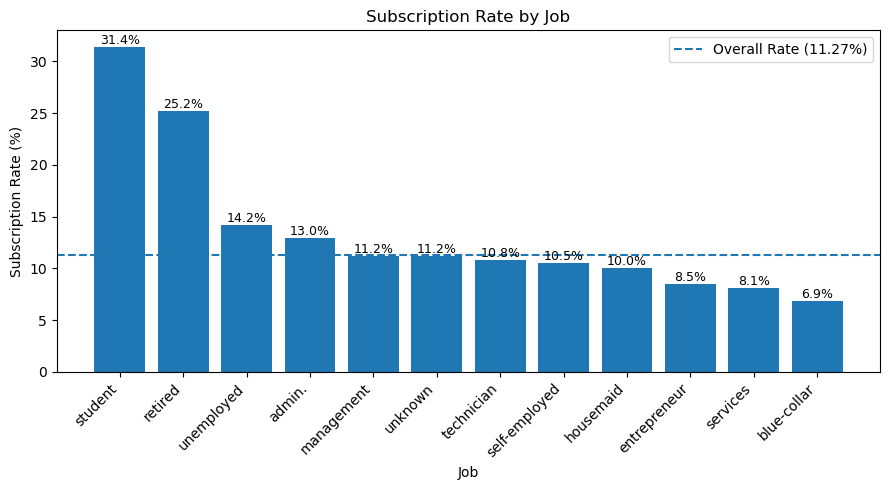

In [61]:
# visualization
job_rate = (
    job_summary["Subscription Rate (%)"]
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    job_rate.index,
    job_rate.values
)

plt.axhline(
    overall_rate,
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Job")

plt.xticks(
    rotation=45,
    ha="right"
)

for bar, value in zip(
    bars,
    job_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.legend()
plt.tight_layout()
plt.show()

**Insight**

- **Student** memiliki historical subscription rate tertinggi sekitar **31.43%**.
- **Retired** berada di urutan berikutnya sekitar **25.23%**.
- **Blue-collar** memiliki subscription rate terendah sekitar **6.89%**.
- Student berada sekitar **20.16 percentage points** di atas overall subscription rate **11.27%**, sedangkan blue-collar sekitar **4.37 percentage points** di bawah overall rate.

Perbedaan tersebut menunjukkan bahwa job category memiliki association dengan historical subscription outcome. Namun, job tidak digunakan sebagai standalone targeting rule karena relationship ini tidak menunjukkan causal effect.

##### Subscription Rate by Contact Channel

In [62]:
contact_summary = (
    df.groupby("contact")["y"]
    .agg(
        Count="size",
        Subscription_Count=lambda x: x.eq("yes").sum()
    )
)

contact_summary["Subscription Rate (%)"] = (
    contact_summary["Subscription_Count"]
    / contact_summary["Count"]
    * 100
)

contact_summary["Difference vs Overall (pp)"] = (
    contact_summary["Subscription Rate (%)"]
    - overall_rate
)

contact_summary = (
    contact_summary
    .sort_values(
        "Subscription Rate (%)",
        ascending=False
    )
)

display(
    contact_summary.round(2)
)

,Count,Subscription_Count,Subscription Rate (%),Difference vs Overall (pp)
contact,,,,
cellular,26144,3853,14.74,3.47
telephone,15044,787,5.23,-6.03


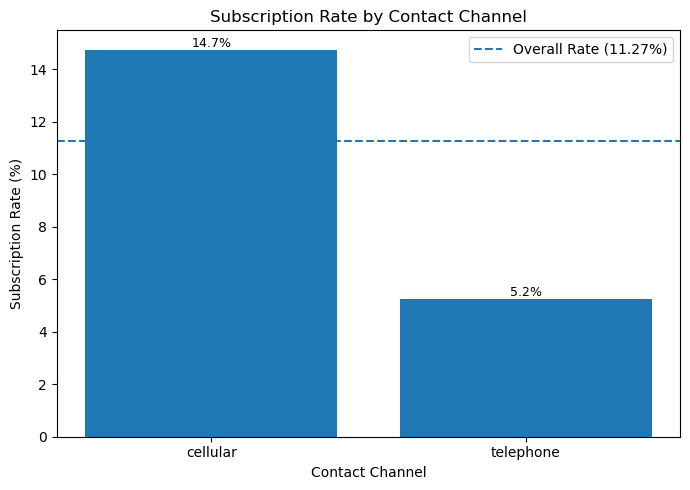

In [63]:
# visualization
contact_rate = (
    contact_summary["Subscription Rate (%)"]
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    contact_rate.index,
    contact_rate.values
)

plt.axhline(
    overall_rate,
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

plt.xlabel("Contact Channel")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Contact Channel")

for bar, value in zip(
    bars,
    contact_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.legend()
plt.tight_layout()
plt.show()

**Insight**

- **Cellular** memiliki historical subscription rate tertinggi sekitar **14.74%**.
- **Telephone** memiliki subscription rate sekitar **5.23%**.
- Cellular berada sekitar **3.47 percentage points** di atas overall rate, sedangkan telephone sekitar **6.03 percentage points** di bawahnya.

Perbedaan ini menunjukkan association antara contact channel dan subscription outcome. Namun, hasil tersebut tidak membuktikan bahwa penggunaan cellular secara langsung menyebabkan subscription rate yang lebih tinggi.

##### Subscription Rate by Campaign Month

In [64]:
month_summary = (
    df.groupby("month")["y"]
    .agg(
        Count="size",
        Subscription_Count=lambda x: x.eq("yes").sum()
    )
)

month_summary["Subscription Rate (%)"] = (
    month_summary["Subscription_Count"]
    / month_summary["Count"]
    * 100
)

month_summary["Difference vs Overall (pp)"] = (
    month_summary["Subscription Rate (%)"]
    - overall_rate
)

month_summary = (
    month_summary
    .sort_values(
        "Subscription Rate (%)",
        ascending=False
    )
)

display(
    month_summary.round(2)
)

,Count,Subscription_Count,Subscription Rate (%),Difference vs Overall (pp)
month,,,,
mar,546,276,50.55,39.28
dec,182,89,48.90,37.64
sep,570,256,44.91,33.65
oct,718,315,43.87,32.61
apr,2632,539,20.48,9.21
aug,6178,655,10.60,-0.66
jun,5318,559,10.51,-0.75
nov,4101,416,10.14,-1.12
jul,7174,649,9.05,-2.22


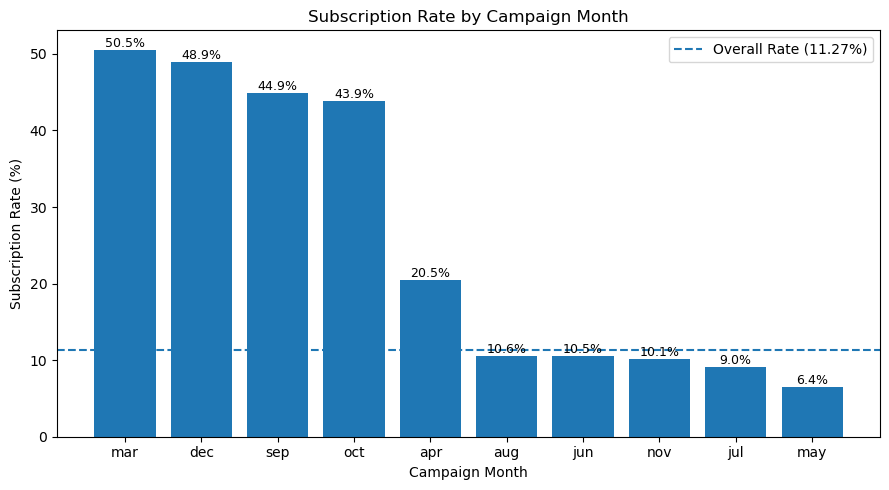

In [65]:
month_rate = (
    month_summary["Subscription Rate (%)"]
)

plt.figure(figsize=(9, 5))

bars = plt.bar(
    month_rate.index,
    month_rate.values
)

plt.axhline(
    overall_rate,
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

plt.xlabel("Campaign Month")
plt.ylabel("Subscription Rate (%)")
plt.title("Subscription Rate by Campaign Month")

for bar, value in zip(
    bars,
    month_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.legend()
plt.tight_layout()
plt.show()

**Insight**

- **March** memiliki historical subscription rate tertinggi sekitar **50.55%**.
- Diikuti oleh **December (48.90%)**, **September (44.91%)**, dan **October (43.87%)**.
- **May** memiliki subscription rate terendah sekitar **6.43%**.
- March berada sekitar **39.28 percentage points** di atas overall rate, sedangkan May sekitar **4.83 percentage points** di bawahnya.

Variation antar campaign month cukup besar. Namun, month tidak diinterpretasikan sebagai causal driver karena campaign period dapat berkaitan dengan campaign strategy, customer composition, dan economic conditions.

##### Subscription Rate by Previous Campaign Outcome

In [66]:
poutcome_summary = (
    df.groupby("poutcome")["y"]
    .agg(
        Count="size",
        Subscription_Count=lambda x: x.eq("yes").sum()
    )
)

poutcome_summary["Subscription Rate (%)"] = (
    poutcome_summary["Subscription_Count"]
    / poutcome_summary["Count"]
    * 100
)

poutcome_summary["Difference vs Overall (pp)"] = (
    poutcome_summary["Subscription Rate (%)"]
    - overall_rate
)

poutcome_summary = (
    poutcome_summary
    .sort_values(
        "Subscription Rate (%)",
        ascending=False
    )
)

display(
    poutcome_summary.round(2)
)

,Count,Subscription_Count,Subscription Rate (%),Difference vs Overall (pp)
poutcome,,,,
success,1373,894,65.11,53.85
failure,4252,605,14.23,2.96
nonexistent,35563,3141,8.83,-2.43


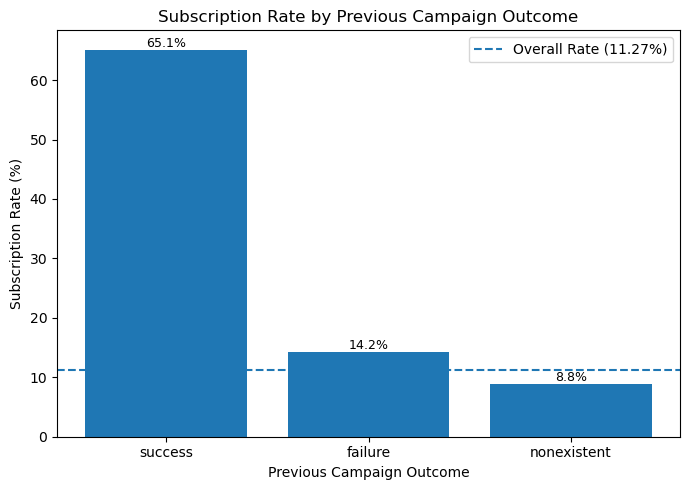

In [67]:
# visualization
poutcome_rate = (
    poutcome_summary["Subscription Rate (%)"]
)

plt.figure(figsize=(7, 5))

bars = plt.bar(
    poutcome_rate.index,
    poutcome_rate.values
)

plt.axhline(
    overall_rate,
    linestyle="--",
    label=f"Overall Rate ({overall_rate:.2f}%)"
)

plt.xlabel("Previous Campaign Outcome")
plt.ylabel("Subscription Rate (%)")
plt.title(
    "Subscription Rate by Previous Campaign Outcome"
)

for bar, value in zip(
    bars,
    poutcome_rate.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.legend()
plt.tight_layout()
plt.show()

**Insight**

- **Previous success** memiliki historical subscription rate tertinggi sekitar **65.11%**.
- **Failure** memiliki rate sekitar **14.23%**.
- **Nonexistent** memiliki rate terendah sekitar **8.83%**.
- Previous success berada sekitar **53.85 percentage points** di atas overall subscription rate **11.27%**.

Previous campaign outcome merupakan salah satu historical signals yang paling kuat secara deskriptif. Namun, hasil ini tetap menunjukkan association dan tidak membuktikan bahwa previous campaign success menyebabkan subscription berikutnya.

In [68]:
production_numerical = [
    col for col in numerical_cols
    if col != "duration"
]

numerical_target_summary = (
    df
    .groupby("y")[production_numerical]
    .median()
    .T
    .rename(
        columns={
            "no": "Median No",
            "yes": "Median Yes"
        }
    )
)

display(
    numerical_target_summary.round(2)
)

y,Median No,Median Yes
age,38.00,37.00
campaign,2.00,2.00
pdays,999.00,999.00
previous,0.00,0.00
emp.var.rate,1.10,-1.80
cons.price.idx,93.92,93.20
cons.conf.idx,-41.80,-40.40
euribor3m,4.86,1.27
nr.employed,5195.80,5099.10


In [69]:
# leakage diagnostic
duration_median = (
    df
    .groupby("y")["duration"]
    .median()
)

display(
    duration_median
    .rename("Median Duration")
    .to_frame()
)

,Median Duration
y,
no,163.5
yes,449.0


### 3.4 Multivariate & Association Analysis

Multivariate dan association analysis digunakan untuk mengevaluasi apakah beberapa patterns tetap terlihat ketika features dianalisis secara bersama-sama serta untuk mengidentifikasi hubungan yang lebih kuat antar features.

#### Previous Campaign Outcome × Campaign Intensity

Previous campaign outcome tetap menunjukkan perbedaan subscription rate pada berbagai tingkat current campaign contact.

| Campaign Contacts | Failure | Nonexistent | Success |
|---|---:|---:|---:|
| 1 | 15.14% | 10.08% | 67.27% |
| 2 | 13.22% | 8.83% | 65.25% |
| 3 | 15.29% | 8.59% | 68.75% |
| 4–5 | 15.04% | 7.38% | 47.30% |
| 6–10 | 6.40% | 5.88% | 38.71% |
| >10 | 0.00% | 3.14% | N/A |

Pada observations tanpa previous campaign outcome (`nonexistent`), historical subscription rate menurun dari **10.08% pada 1 contact** menjadi **3.14% pada >10 contacts**.

Previous `success` tetap menunjukkan subscription rate yang jauh lebih tinggi pada contact groups dengan jumlah observations yang memadai.

Temuan ini menunjukkan bahwa **historical response dan contact intensity memberikan informasi yang lebih meaningful ketika dianalisis bersama**, tetapi tidak menunjukkan causal effect dari penambahan contact.


In [70]:
campaign_df = df.copy()

# Group number of contacts in current campaign
campaign_df["campaign_group"] = pd.cut(
    campaign_df["campaign"],
    bins=[0, 1, 2, 3, 5, 10, float("inf")],
    labels=["1", "2", "3", "4-5", "6-10", ">10"]
)

# Overall subscription rate by current campaign contact count

campaign_group_summary = (
    campaign_df
    .groupby(
        "campaign_group",
        observed=False
    )["y"]
    .agg(
        Count="size",
        Subscription=lambda x: x.eq("yes").sum()
    )
)

campaign_group_summary[
    "Subscription Rate (%)"
] = (
    campaign_group_summary["Subscription"]
    / campaign_group_summary["Count"]
    * 100
)

display(
    campaign_group_summary.round(2)
)

# Calculate subscription rate by campaign intensity and previous outcome
campaign_poutcome = (
    campaign_df
    .groupby(
        ["campaign_group", "poutcome"],
        observed=False
    )["y"]
    .agg(
        Count="size",
        Subscription=lambda x: x.eq("yes").sum()
    )
    .reset_index()
)

campaign_poutcome["Subscription Rate (%)"] = (
    campaign_poutcome["Subscription"]
    / campaign_poutcome["Count"]
    * 100
)

# Compact output
campaign_poutcome_pivot = (
    campaign_poutcome
    .pivot(
        index="campaign_group",
        columns="poutcome",
        values="Subscription Rate (%)"
    )
)

display(
    campaign_poutcome_pivot.round(2)
)

,Count,Subscription,Subscription Rate (%)
campaign_group,,,
1,17642,2300,13.04
2,10570,1211,11.46
3,5341,574,10.75
4-5,4250,369,8.68
6-10,2516,159,6.32
>10,869,27,3.11


poutcome,failure,nonexistent,success
campaign_group,,,
1,15.14,10.08,67.27
2,13.22,8.83,65.25
3,15.29,8.59,68.75
4-5,15.04,7.38,47.30
6-10,6.40,5.88,38.71
>10,0.00,3.14,NaN


#### Contact Method × Month

Historical subscription rate juga berbeda ketika contact method dan campaign month dianalisis secara bersama.

Sebagai contoh:

- **June:** cellular **42.56%** vs telephone **4.67%**
- **May:** cellular **11.13%** vs telephone **3.30%**

Namun, perbedaan tersebut tidak dapat diinterpretasikan sebagai causal effect dari communication channel karena campaign month, economic conditions, dan campaign strategy dapat saling berkaitan.

Oleh karena itu, channel dan timing diperlakukan sebagai **campaign-context signals**, bukan independent causal drivers.

In [71]:
contact_month = (
    df
    .groupby(
        ["month", "contact"]
    )["y"]
    .apply(
        lambda x: x.eq("yes").mean() * 100
    )
    .unstack()
)

display(
    #contact_month.round(2)
    contact_month
    .loc[
        ["jun", "may"]
    ]
    .round(2)
)

contact,cellular,telephone
month,,
jun,42.56,4.67
may,11.13,3.30


#### Numerical Feature Association

Spearman correlation digunakan untuk mengevaluasi **direction dan strength of association antar numerical features**.

Metode ini dipilih karena beberapa numerical features memiliki **skewed distribution dan extreme values**, sehingga pendekatan rank-based Spearman lebih sesuai untuk melihat monotonic relationship.

In [72]:
# spearman_corr + top_correlations
spearman_corr = (
    df[numerical_cols]
    .corr(method="spearman")
)

upper_mask = np.triu(
    np.ones(spearman_corr.shape, dtype=bool),
    k=1
)

top_correlations = (
    spearman_corr
    .where(upper_mask)
    .stack()
    .rename("Spearman Correlation")
    .reset_index()
    .rename(
        columns={
            "level_0": "Feature 1",
            "level_1": "Feature 2"
        }
    )
)

top_correlations["Absolute Correlation"] = (
    top_correlations[
        "Spearman Correlation"
    ].abs()
)

In [73]:
display(
    top_correlations
    .sort_values(
        "Absolute Correlation",
        ascending=False
    )
    .head(10)
    [
        [
            "Feature 1",
            "Feature 2",
            "Spearman Correlation"
        ]
    ]
    .round(3)
)

,Feature 1,Feature 2,Spearman Correlation
38,emp.var.rate,nr.employed,0.945
37,emp.var.rate,euribor3m,0.940
44,euribor3m,nr.employed,0.929
35,emp.var.rate,cons.price.idx,0.665
24,pdays,previous,-0.510
40,cons.price.idx,euribor3m,0.491
41,cons.price.idx,nr.employed,0.465
33,previous,euribor3m,-0.455
34,previous,nr.employed,-0.439
30,previous,emp.var.rate,-0.435


##### Spearman Correlation Heatmap

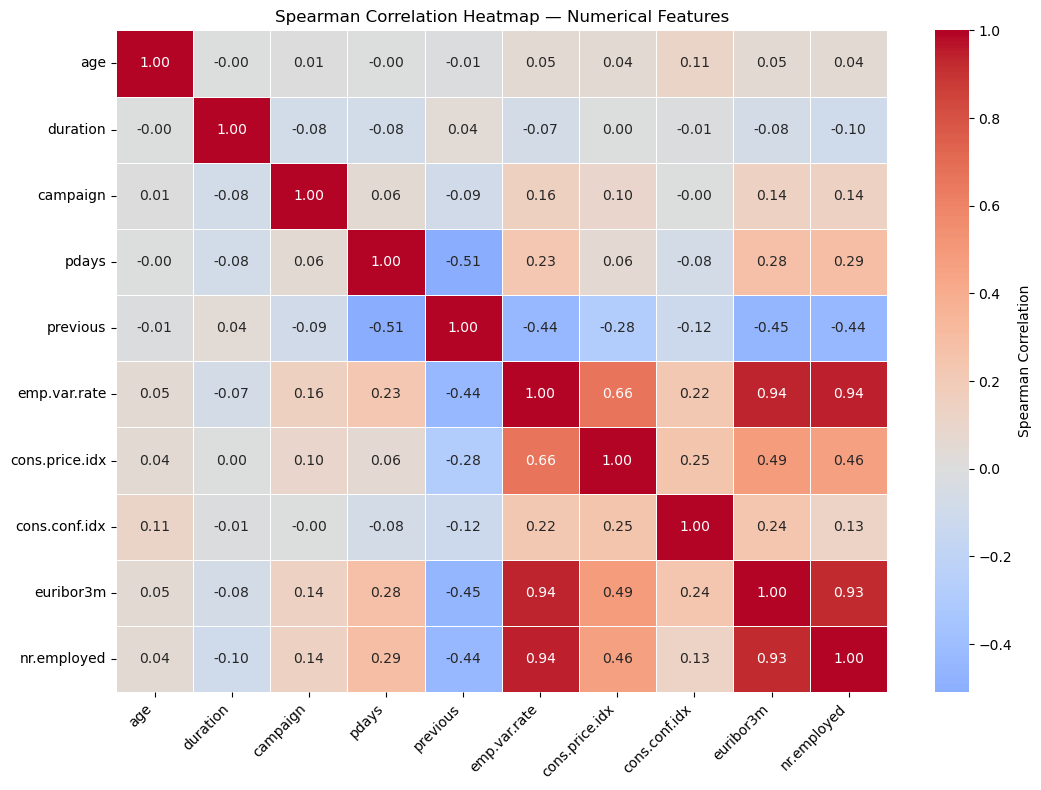

In [74]:
plt.figure(figsize=(11, 8))

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5,
    cbar_kws={
        "label": "Spearman Correlation"
    }
)

plt.title(
    "Spearman Correlation Heatmap — Numerical Features"
)

plt.xticks(
    rotation=45,
    ha="right"
)

plt.yticks(
    rotation=0
)

plt.tight_layout()
plt.show()

**Insight**

Heatmap menunjukkan beberapa relationships yang sangat kuat antar economic indicators:

- `emp.var.rate` dan `nr.employed` memiliki strong positive correlation sekitar **0.945**;
- `emp.var.rate` dan `euribor3m` memiliki strong positive correlation sekitar **0.940**;
- `euribor3m` dan `nr.employed` memiliki strong positive correlation sekitar **0.929**;
- `emp.var.rate` dan `cons.price.idx` menunjukkan positive correlation sekitar **0.665**.

Selain itu, `pdays` dan `previous` menunjukkan negative correlation sekitar **-0.510**.

Strong correlation antara `emp.var.rate`, `euribor3m`, dan `nr.employed` menunjukkan bahwa features tersebut membawa overlapping information mengenai economic conditions.

Correlation menunjukkan bagaimana dua variables bergerak bersama dalam historical data, tetapi tidak membuktikan bahwa satu variable menyebabkan perubahan pada variable lainnya.

,Feature,Spearman Correlation
1,duration,0.349
3,pdays,-0.325
9,nr.employed,-0.284
8,euribor3m,-0.267
5,emp.var.rate,-0.247
4,previous,0.201


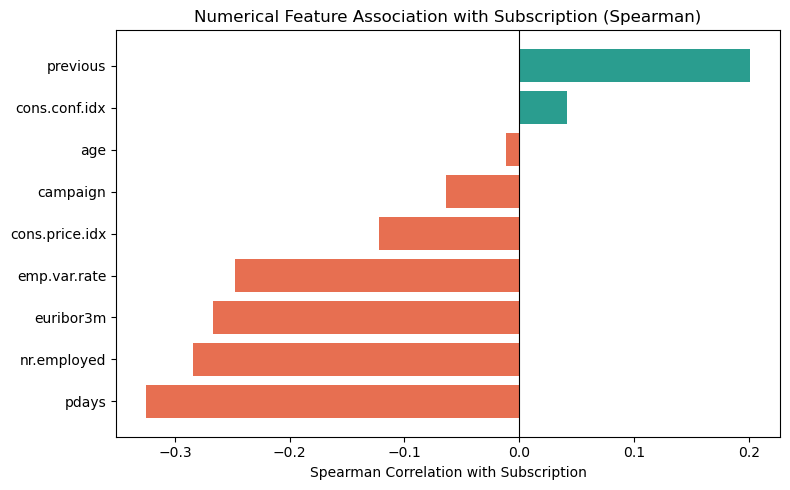

In [75]:
# Numerical feature-to-target association

target_binary = (
    df["y"]
    .map({
        "no": 0,
        "yes": 1
    })
)

numerical_target_corr = (
    df[numerical_cols]
    .corrwith(
        target_binary,
        method="spearman"
    )
    .rename("Spearman Correlation")
    .reset_index()
    .rename(
        columns={
            "index": "Feature"
        }
    )
)

numerical_target_corr[
    "Absolute Correlation"
] = (
    numerical_target_corr[
        "Spearman Correlation"
    ].abs()
)

display(
    numerical_target_corr
    .sort_values(
        "Absolute Correlation",
        ascending=False
    )
    .head(6)
    [
        [
            "Feature",
            "Spearman Correlation"
        ]
    ]
    .round(3)
)

# Exclude duration because it is only known after the call (data leakage).
numerical_plot = (
    numerical_target_corr
    .query("Feature != 'duration'")
    .sort_values("Spearman Correlation")
)

plt.figure(figsize=(8, 5))
colors = np.where(numerical_plot["Spearman Correlation"] >= 0, "#2a9d8f", "#e76f51")
plt.barh(numerical_plot["Feature"], numerical_plot["Spearman Correlation"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Numerical Feature Association with Subscription (Spearman)")
plt.xlabel("Spearman Correlation with Subscription")
plt.tight_layout()
plt.show()

#### Numerical-to-Target Association Interpretation

Terhadap target, beberapa numerical features menunjukkan association yang lebih menonjol.

`duration` memiliki association positif paling tinggi, tetapi tetap diperlakukan sebagai **leakage diagnostic** karena nilainya baru tersedia setelah contact berlangsung.

`pdays` menunjukkan association negatif yang relatif kuat, tetapi perlu diinterpretasikan dengan hati-hati karena sebagian besar observations memiliki special value `999`.

Economic indicators seperti `nr.employed`, `euribor3m`, dan `emp.var.rate` juga menunjukkan association dengan subscription outcome.

Correlation digunakan sebagai **descriptive association** dan tidak menjadi dasar otomatis untuk menghapus feature maupun menyimpulkan causal relationship.

#### Categorical Association with Target

Cramer's V digunakan untuk mengukur strength of association antara categorical features dan subscription outcome.

| Feature | Cramer's V |
|---|---:|
| `poutcome` | **0.320** |
| `month` | **0.274** |
| `job` | **0.153** |
| `contact` | **0.145** |
| `default` | 0.099 |

`poutcome` menunjukkan association terbesar terhadap target di antara categorical features, diikuti oleh `month`.

`housing` dan `loan` memiliki association yang sangat lemah.

Association strength digunakan sebagai supporting evidence dan tidak menunjukkan causal relationship.

,Feature,Cramer's V
9,poutcome,0.320
7,month,0.274
0,job,0.153
6,contact,0.145
3,default,0.099


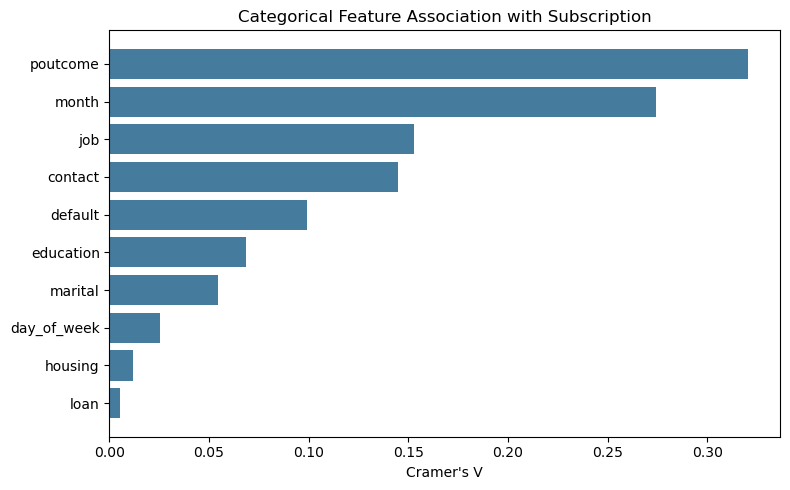

In [76]:
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    contingency_table = pd.crosstab(x, y)

    chi2 = chi2_contingency(
        contingency_table,
        correction=False
    )[0]

    n = contingency_table.to_numpy().sum()
    rows, cols = contingency_table.shape

    phi2 = chi2 / n

    return np.sqrt(
        phi2 / min(rows - 1, cols - 1)
    )


categorical_cols = (
    df
    .select_dtypes(include="object")
    .columns
    .drop("y")
)

categorical_association = []

for col in categorical_cols:

    association = cramers_v(
        df[col],
        df["y"]
    )

    categorical_association.append({
        "Feature": col,
        "Cramer's V": association
    })

categorical_association = (
    pd.DataFrame(categorical_association)
    .sort_values(
        "Cramer's V",
        ascending=False
    )
)

display(
    categorical_association
    .head(5)
    .round(3)
)

categorical_plot = categorical_association.sort_values("Cramer's V")
plt.figure(figsize=(8, 5))
plt.barh(categorical_plot["Feature"], categorical_plot["Cramer's V"], color="#457b9d")
plt.title("Categorical Feature Association with Subscription")
plt.xlabel("Cramer's V")
plt.tight_layout()
plt.show()

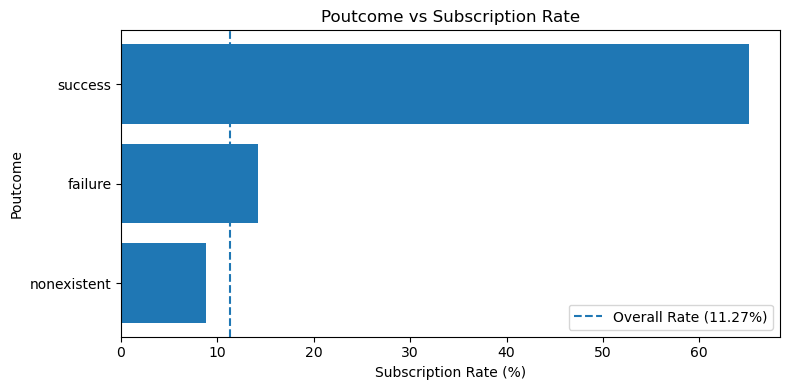

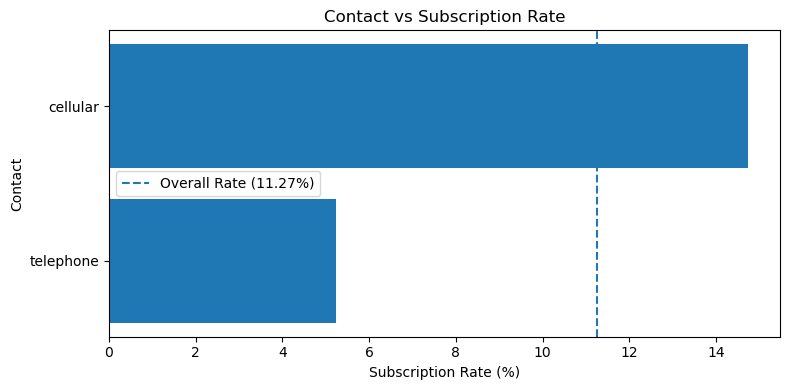

In [77]:
selected_categorical_cols = [
    "poutcome",
    "contact"
]

overall_rate = (
    df["y"].eq("yes").mean() * 100
)

for col in selected_categorical_cols:

    subscription_rate = (
        df
        .groupby(col)["y"]
        .apply(
            lambda x: x.eq("yes").mean() * 100
        )
        .sort_values()
    )

    plt.figure(figsize=(8, 4))

    plt.barh(
        subscription_rate.index,
        subscription_rate.values
    )

    plt.axvline(
        overall_rate,
        linestyle="--",
        label=f"Overall Rate ({overall_rate:.2f}%)"
    )

    plt.title(
        f"{col.replace('_', ' ').title()} vs Subscription Rate"
    )

    plt.xlabel("Subscription Rate (%)")
    plt.ylabel(
        col.replace("_", " ").title()
    )

    plt.legend()
    plt.tight_layout()
    plt.show()

### 3.5 Statistical Validation

Statistical tests digunakan untuk memvalidasi selected relationships yang ditemukan pada EDA. Karena ukuran sample cukup besar, interpretation tidak hanya menggunakan **p-value**, tetapi juga mempertimbangkan **effect size**.

#### Categorical Features vs Target

Chi-Square Test of Independence digunakan untuk mengevaluasi association antara selected categorical features dan subscription outcome.

| Feature | Chi-Square | p-value | Cramer's V |
|---|---:|---:|---:|
| `poutcome` | 4230.52 | < 0.001 | **0.320** |
| `month` | 3101.15 | < 0.001 | **0.274** |
| `job` | 961.24 | < 0.001 | **0.153** |
| `contact` | 863.27 | < 0.001 | **0.145** |

Seluruh selected categorical features menunjukkan statistical association dengan target.

Namun, karena sample size besar, statistical significance perlu dibaca bersama effect size. `poutcome` dan `month` menunjukkan association yang lebih kuat dibanding `job` dan `contact`.

In [78]:
from scipy.stats import chi2_contingency

selected_categorical = [
    "poutcome",
    "month",
    "job",
    "contact"
]

chi_square_results = []

for col in selected_categorical:

    table = pd.crosstab(
        df[col],
        df["y"]
    )

    chi2, p_value, _, _ = chi2_contingency(
        table,
        correction=False
    )

    v = cramers_v(
        df[col],
        df["y"]
    )

    chi_square_results.append({
        "Feature": col,
        "Chi-Square": chi2,
        "p-value": p_value,
        "Cramer's V": v
    })

chi_square_results = (
    pd.DataFrame(chi_square_results)
    .sort_values(
        "Cramer's V",
        ascending=False
    )
)

display(
    chi_square_results.round(3)
)

,Feature,Chi-Square,p-value,Cramer's V
0,poutcome,4230.524,0.0,0.320
1,month,3101.149,0.0,0.274
2,job,961.242,0.0,0.153
3,contact,863.269,0.0,0.145


#### Numerical Features vs Target

Karena beberapa numerical features memiliki skewed distribution, digunakan **Mann–Whitney U Test** untuk membandingkan distribution antara subscriber dan non-subscriber.

| Feature | Median No | Median Yes | p-value | Rank-Biserial Correlation |
|---|---:|---:|---:|---:|
| `nr.employed` | 5195.8 | 5099.1 | < 0.001 | **-0.498** |
| `euribor3m` | 4.857 | 1.266 | < 0.001 | **-0.487** |
| `emp.var.rate` | 1.1 | -1.8 | < 0.001 | **-0.434** |
| `previous` | 0 | 0 | < 0.001 | **0.219** |
| `campaign` | 2 | 2 | < 0.001 | **-0.110** |

Economic indicators seperti `nr.employed`, `euribor3m`, dan `emp.var.rate` menunjukkan effect size yang lebih besar dibanding `campaign`.

`campaign` tetap statistically significant, tetapi memiliki effect size yang relatif kecil. Hal ini menunjukkan bahwa **statistical significance tidak selalu berarti practical atau business significance yang besar**.

Statistical validation mendukung beberapa findings utama EDA, tetapi seluruh hasil tetap menunjukkan **association, bukan causal relationship**.

In [79]:
from scipy.stats import mannwhitneyu

selected_numerical = [
    "euribor3m",
    "nr.employed",
    "emp.var.rate",
    "previous",
    "campaign"
]

mann_whitney_results = []

for col in selected_numerical:

    yes_group = df.loc[
        df["y"] == "yes",
        col
    ]

    no_group = df.loc[
        df["y"] == "no",
        col
    ]

    u_stat, p_value = mannwhitneyu(
        yes_group,
        no_group,
        alternative="two-sided"
    )

    rank_biserial = (
        2 * u_stat /
        (
            len(yes_group)
            * len(no_group)
        )
        - 1
    )

    mann_whitney_results.append({
        "Feature": col,
        "Median No": no_group.median(),
        "Median Yes": yes_group.median(),
        "p-value": p_value,
        "Rank-Biserial Correlation": rank_biserial
    })

mann_whitney_results = pd.DataFrame(
    mann_whitney_results
)

display(
    mann_whitney_results.round(3)
)

,Feature,Median No,Median Yes,p-value,Rank-Biserial Correlation
0,euribor3m,4.857,1.266,0.0,-0.487
1,nr.employed,5195.800,5099.100,0.0,-0.498
2,emp.var.rate,1.100,-1.800,0.0,-0.434
3,previous,0.000,0.000,0.0,0.219
4,campaign,2.000,2.000,0.0,-0.110


### 3.6 Key EDA Findings

EDA menunjukkan beberapa patterns utama yang relevan terhadap subscription dan campaign prioritization:

| Finding | Evidence | EDA Interpretation |
|---|---|---|
| **Previous campaign response merupakan historical signal yang kuat** | `poutcome = success` memiliki subscription rate **65.11%** dibanding overall rate **11.27%**, dengan Cramer's V **0.320**. | Historical campaign response menunjukkan association yang kuat dengan subscription outcome. |
| **Repeated contact tidak diikuti subscription rate yang lebih tinggi** | Overall subscription rate menurun dari **13.04% pada 1 contact** menjadi sekitar **3.11% pada >10 contacts**. | Contact intensity yang lebih tinggi tidak secara deskriptif menunjukkan response yang lebih tinggi. |
| **Campaign context menunjukkan perbedaan historical response** | Cellular memiliki subscription rate **14.74%** dibanding telephone **5.23%**, sementara subscription rate juga berbeda cukup besar antar campaign month. | Channel dan timing membawa contextual information, tetapi tidak menunjukkan causal effect. |
| **Economic conditions memiliki association dengan subscription** | `nr.employed`, `euribor3m`, dan `emp.var.rate` menunjukkan effect size dan correlation yang relatif lebih kuat terhadap subscription dibanding beberapa numerical features lainnya. | Subscription pattern berkaitan dengan economic environment selama campaign period. |
| **`duration` sangat informative tetapi tidak valid untuk pre-contact prediction** | `duration` memiliki Spearman correlation sekitar **0.349** dan median lebih tinggi pada subscriber. | Karena hanya tersedia setelah contact berlangsung, `duration` merupakan post-contact leakage dan tidak digunakan pada pre-contact prediction model. |

Secara keseluruhan, subscription outcome berkaitan dengan kombinasi **previous campaign history, campaign context, contact intensity, client characteristics, dan economic conditions**.

Seluruh findings pada EDA merupakan **associational evidence** dan tidak digunakan untuk menyimpulkan causal relationship.

## 4. Preprocessing

### 4.1 Preprocessing Decisions

Preprocessing strategy ditentukan berdasarkan **feature type, distribution, cardinality, business meaning, dan availability at scoring time**.

Tujuannya bukan sekadar membersihkan data, tetapi memastikan setiap feature diproses dengan cara yang sesuai dan hanya menggunakan informasi yang tersedia ketika prediction dilakukan.

| Treatment | Features | Decision |
|---|---|---|
| **StandardScaler** | `cons.price.idx`, `cons.conf.idx` | Digunakan pada numerical features dengan distribution relatif lebih symmetric |
| **RobustScaler** | `age`, `campaign`, `previous`, `emp.var.rate`, `euribor3m`, `nr.employed` | Digunakan pada numerical features dengan skewness atau extreme values |
| **Special Treatment** | `pdays` | Nilai `999` memiliki business meaning dan ditangani melalui feature engineering sebelum scaling |
| **One Hot Encoding** | `marital`, `default`, `housing`, `loan`, `contact`, `day_of_week`, `poutcome` | Digunakan pada nominal categorical features dengan cardinality ≤ 5 |
| **Binary Encoding** | `job`, `education`, `month` | Digunakan pada nominal categorical features dengan cardinality > 5 untuk membatasi pertambahan jumlah columns |
| **Ordinal Encoding** | — | Tidak digunakan karena tidak terdapat genuine ordinal feature yang memiliki urutan business yang jelas |
| **Retain as Category** | `unknown`, `nonexistent` | Dipertahankan karena memiliki semantic / structural meaning |
| **Exclude from Modeling** | `duration` | Post-contact leakage dan tidak tersedia pada scoring time |

#### Data Cleaning Rationale

Data cleaning tidak dilakukan hanya karena suatu nilai terlihat tidak biasa. Setiap treatment ditentukan berdasarkan **data characteristics, business meaning, dan kemungkinan penggunaannya pada saat prediction**.

##### 1. `duration` — Excluded Due to Post-Contact Leakage

Feature `duration` menunjukkan durasi phone call dengan client.

Pada business use case project ini, model melakukan scoring **selama campaign execution, sebelum contact attempt dilakukan**. Pada decision point tersebut, durasi phone call belum diketahui.

Jika `duration` digunakan sebagai modeling feature, model akan memperoleh information yang hanya tersedia **setelah interaction berlangsung**. Kondisi ini disebut **data leakage**, karena model menggunakan information dari masa depan yang tidak tersedia ketika prediction sebenarnya dilakukan.

Akibatnya, model performance pada historical data dapat terlihat lebih tinggi, tetapi performance tersebut tidak merepresentasikan kondisi penggunaan model yang sebenarnya.

Oleh karena itu:

- `duration` tetap digunakan pada EDA sebagai **leakage diagnostic**;
- `duration` **tidak digunakan sebagai modeling feature**;
- feature ini tidak dihapus dari original dataset, tetapi hanya dikeluarkan dari production-oriented feature set.

##### 2. Missing Values dan Semantic Missing

Original dataset tidak memiliki actual missing value (`NaN`). Oleh karena itu, tidak dilakukan general missing-value imputation menggunakan mean, median, maupun KNNImputer.

Beberapa categorical features memiliki value `unknown`. Value tersebut tidak langsung diimputasi karena dapat merepresentasikan **semantic missing information** dan masih dapat membawa predictive information.

Karena tidak terdapat dasar yang cukup untuk menentukan nilai pengganti yang benar, category `unknown` dipertahankan sebagai category tersendiri.

Demikian juga, `poutcome = nonexistent` bukan actual missing value. Category tersebut menunjukkan bahwa tidak terdapat previous campaign outcome dan dipertahankan sebagai valid structural category.

##### 3. `pdays = 999` — Special Business Value

Pada feature `pdays`, nilai `999` tidak merepresentasikan jumlah hari biasa. Nilai tersebut menunjukkan bahwa client **belum pernah dihubungi pada previous campaign**.

Karena itu, nilai `999` tidak diperlakukan sebagai outlier atau langsung diimputasi.

Informasinya dipisahkan melalui feature engineering menjadi:

- `previously_contacted` — menunjukkan apakah client pernah dihubungi sebelumnya;
- `pdays_clean` — menyimpan jumlah hari sejak previous contact untuk client yang memang pernah dihubungi.

Detail feature engineering dijelaskan pada Section 4.2.

##### 4. `education` — Tidak Menggunakan Ordinal Encoding

Meskipun beberapa category pada `education` terlihat memiliki level pendidikan yang berbeda, kategorinya tidak membentuk urutan linear yang sepenuhnya jelas untuk business interpretation dan modeling.

Karena itu, `education` tidak dipaksakan menggunakan Ordinal Encoding dan diperlakukan sebagai nominal categorical feature.

Dengan demikian, preprocessing dilakukan berdasarkan **business meaning dan karakteristik data**, bukan hanya berdasarkan data type.

In [80]:
standard_num_cols = [
    "cons.price.idx",
    "cons.conf.idx"
]

robust_num_cols = [
    "age",
    "campaign",
    "previous",
    "emp.var.rate",
    "euribor3m",
    "nr.employed"
]

onehot_cols = [
    "marital",
    "default",
    "housing",
    "loan",
    "contact",
    "day_of_week",
    "poutcome"
]

binary_cols = [
    "job",
    "education",
    "month"
]

### 4.2 Additional Feature Engineering

Feature engineering dilakukan hanya ketika memiliki **business meaning** dan membantu merepresentasikan informasi secara lebih tepat.

#### `pdays` — Previous Contact Information

Pada feature `pdays`, nilai `999` menunjukkan bahwa client **belum pernah dihubungi pada previous campaign**. Nilai tersebut tidak diperlakukan sebagai jumlah hari biasa.

Dibuat dua features baru:

| New Feature | Logic | Business Meaning |
|---|---|---|
| `previously_contacted` | `1` jika `pdays != 999`, selain itu `0` | Menunjukkan apakah client pernah dihubungi pada previous campaign |
| `pdays_clean` | Nilai `pdays` jika pernah dihubungi, selain itu `NaN` | Menyimpan jumlah hari sejak previous contact |

Original `pdays` tidak digunakan secara langsung setelah feature engineering karena informasinya telah direpresentasikan melalui `previously_contacted` dan `pdays_clean`.

Feature engineering dilakukan di dalam preprocessing pipeline agar transformation yang sama diterapkan secara konsisten pada training dan future data.

In [81]:
def add_pdays_features(X):
    X = X.copy()

    X["previously_contacted"] = (
        X["pdays"] != 999
    ).astype(int)

    X["pdays_clean"] = (
        X["pdays"]
        .replace(999, np.nan)
    )

    return X

### 4.3 ColumnTransformer & Pipeline

`ColumnTransformer` digunakan untuk menerapkan preprocessing yang berbeda pada setiap kelompok feature berdasarkan karakteristiknya.

Preprocessing yang diterapkan:

| Feature Group | Transformation |
|---|---|
| Standard numerical | `StandardScaler` |
| Robust numerical | `RobustScaler` |
| Low-cardinality categorical | `OneHotEncoder(handle_unknown="ignore")` |
| High-cardinality categorical | `BinaryEncoder` |
| `pdays_clean` | Median Imputation + `RobustScaler` |
| `previously_contacted` | Passthrough |

Median imputation pada `pdays_clean` diperlukan karena feature engineering secara sengaja mengubah `pdays = 999` menjadi `NaN`. Ini berbeda dari actual missing values pada original dataset.

Original `pdays` tidak digunakan setelah feature engineering karena informasinya telah direpresentasikan melalui `previously_contacted` dan `pdays_clean`.

Seluruh transformation kemudian digabungkan dalam satu preprocessing pipeline:

**Raw Features → Feature Engineering → ColumnTransformer**

Model belum dimasukkan pada tahap ini karena model selection dilakukan pada Section 5.

In [82]:
!pip install -q category-encoders

from category_encoders import BinaryEncoder

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    RobustScaler,
    OneHotEncoder,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer

In [83]:
# special columns + pdays pipeline
pdays_clean_col = [
    "pdays_clean"
]

previously_contacted_col = [
    "previously_contacted"
]

pdays_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    ),
    (
        "scaler",
        RobustScaler()
    )
])

In [84]:
# ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num_standard",
            StandardScaler(),
            standard_num_cols
        ),
        (
            "num_robust",
            RobustScaler(),
            robust_num_cols
        ),
        (
            "cat_onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            onehot_cols
        ),
        (
            "cat_binary",
            BinaryEncoder(),
            binary_cols
        ),
        (
            "pdays",
            pdays_pipeline,
            pdays_clean_col
        ),
        (
            "previously_contacted",
            "passthrough",
            previously_contacted_col
        )
    ],
    remainder="drop"
)

In [85]:
# preprocessing pipeline
feature_engineering = FunctionTransformer(
    add_pdays_features,
    validate=False
)

preprocessing_pipeline = Pipeline([
    (
        "feature_engineering",
        feature_engineering
    ),
    (
        "preprocessor",
        preprocessor
    )
])

### 4.4 Leakage Validation

Leakage validation dilakukan untuk memastikan bahwa preprocessing dan feature engineering hanya menggunakan informasi yang tersedia pada saat prediction.

Validation rules:

- Train-test split dilakukan **sebelum fitting preprocessing**.
- Scaling, encoding, dan imputation hanya di-fit menggunakan training data.
- `duration` dikeluarkan dari production-oriented feature set karena baru diketahui setelah contact selesai.
- Feature engineering `pdays` hanya menggunakan informasi dari feature tersebut dan tidak menggunakan target.
- `unknown`, `999`, dan `nonexistent` ditangani berdasarkan business meaning, bukan target information.
- Oversampling atau resampling hanya dilakukan pada training fold selama modeling.
- Test set tetap **untouched** sampai final model evaluation.

Dengan struktur:

**Raw Features → Feature Engineering → ColumnTransformer → Model**

seluruh preprocessing dapat diterapkan secara konsisten tanpa fitting transformer pada keseluruhan dataset.

In [86]:
production_features = [
    "age",
    "job",
    "marital",
    "education",
    "default",
    "housing",
    "loan",
    "contact",
    "month",
    "day_of_week",
    "campaign",
    "pdays",
    "previous",
    "poutcome",
    "emp.var.rate",
    "cons.price.idx",
    "cons.conf.idx",
    "euribor3m",
    "nr.employed"
]

assert "duration" not in production_features

print(
    "Production features:",
    len(production_features)
)

print(
    "Duration excluded:",
    "duration" not in production_features
)

Production features: 19
Duration excluded: True


## 5. Modeling

### 5.1 Train-Test Split & Naive Baseline

Dataset dibagi menjadi **training set (80%)** dan **test set (20%)** menggunakan stratified sampling agar proporsi target tetap konsisten.

| Dataset | Observations | Positive Class |
|---|---:|---:|
| Training | 32,950 | 11.27% |
| Test | 8,238 | 11.26% |

Test set disimpan sebagai **untouched holdout set** dan tidak digunakan selama model benchmarking, imbalance treatment, model selection, maupun hyperparameter tuning.

#### Naive Baseline

`DummyClassifier(strategy="most_frequent")` digunakan sebagai naive baseline dengan selalu memprediksi majority class (`no`).

Baseline dievaluasi menggunakan **5-fold Stratified Cross Validation pada training data**.

| Metric | CV Mean |
|---|---:|
| Accuracy | 0.8873 |
| Precision | 0.0000 |
| Recall | 0.0000 |
| F1-score | 0.0000 |
| ROC-AUC | 0.5000 |
| AP | 0.1127 |

Meskipun Accuracy mencapai **88.73%**, baseline sama sekali tidak dapat mengidentifikasi positive class.

AP sebesar **0.1127** mendekati prevalence positive class sebesar 11.27% dan digunakan sebagai reference point awal untuk mengevaluasi candidate models.

In [87]:
# Train-test split
from sklearn.model_selection import train_test_split

X = df[production_features].copy()

y = df["y"].map({
    "no": 0,
    "yes": 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)
print(f"Train positive rate: {y_train.mean():.2%}")
print(f"Test positive rate: {y_test.mean():.2%}")

Training shape: (32950, 19)
Test shape: (8238, 19)
Train positive rate: 11.27%
Test positive rate: 11.26%


In [88]:
#Cross-validation & metrics
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate
)

from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

scoring = {
    "accuracy": "accuracy",
    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),
    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),
    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),
    "roc_auc": "roc_auc",
    "ap": "average_precision"
}

In [89]:
# General model pipeline
def build_model_pipeline(model):

    return Pipeline([
        (
            "feature_engineering",
            feature_engineering
        ),
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            model
        )
    ])

In [90]:
# Dummy baseline
from sklearn.dummy import DummyClassifier

dummy_pipeline = build_model_pipeline(
    DummyClassifier(
        strategy="most_frequent",
        random_state=42
    )
)

dummy_cv = cross_validate(
    dummy_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=-1
)

In [91]:
# Baseline result
baseline_result = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "AP"
    ],
    "CV Mean": [
        dummy_cv["test_accuracy"].mean(),
        dummy_cv["test_precision"].mean(),
        dummy_cv["test_recall"].mean(),
        dummy_cv["test_f1"].mean(),
        dummy_cv["test_roc_auc"].mean(),
        dummy_cv["test_ap"].mean()
    ]
})

display(
    baseline_result.round(4)
)

,Metric,CV Mean
0,Accuracy,0.8873
1,Precision,0.0000
2,Recall,0.0000
3,F1-score,0.0000
4,ROC-AUC,0.5000
5,AP,0.1127


### 5.2 Model Benchmarking

Empat classification models dibandingkan menggunakan **feature set, preprocessing pipeline, training data, dan 5-fold Stratified Cross Validation yang sama**.

Model yang dievaluasi:

- **Logistic Regression** — linear and interpretable baseline.
- **Random Forest** — tree ensemble untuk menangkap non-linear relationships.
- **Extra Trees** — randomized tree ensemble.
- **Gradient Boosting** — sequential ensemble yang memperbaiki prediction error secara bertahap.

Pada tahap ini belum diterapkan class imbalance treatment.

Model dibandingkan menggunakan **Average Precision (AP) sebagai primary metric**, dengan Accuracy, Precision, Recall, F1-score, dan ROC-AUC sebagai supporting metrics.

In [92]:
#1. Define Candidate Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier
)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "Extra Trees": ExtraTreesClassifier(
        n_estimators=200,
        random_state=42,
        n_jobs=1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
0,Gradient Boosting,0.9002,0.6646,0.2322,0.3437,0.7933,0.4608
1,Logistic Regression,0.8997,0.6640,0.2225,0.3331,0.7875,0.4421
2,Random Forest,0.8925,0.5471,0.2791,0.3692,0.7718,0.4149
3,Extra Trees,0.8817,0.4605,0.2885,0.3546,0.7490,0.3291


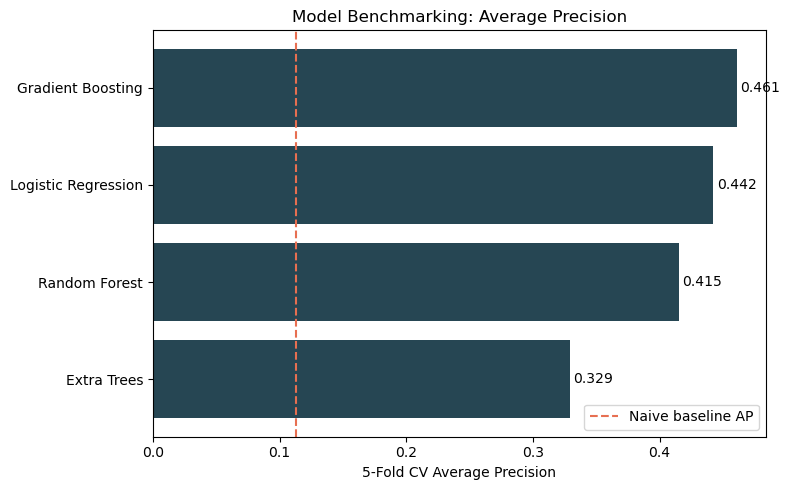

In [93]:
#2. Run Benchmarking
benchmark_results = []

for model_name, model in models.items():

    pipeline = build_model_pipeline(model)

    cv_result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    benchmark_results.append({
        "Model": model_name,
        "Accuracy": cv_result["test_accuracy"].mean(),
        "Precision": cv_result["test_precision"].mean(),
        "Recall": cv_result["test_recall"].mean(),
        "F1-score": cv_result["test_f1"].mean(),
        "ROC-AUC": cv_result["test_roc_auc"].mean(),
        "AP": cv_result["test_ap"].mean()
    })

benchmark_df = (
    pd.DataFrame(benchmark_results)
    .sort_values(
        "AP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    benchmark_df.round(4)
)

benchmark_plot = benchmark_df.sort_values("AP")
plt.figure(figsize=(8, 5))
bars = plt.barh(benchmark_plot["Model"], benchmark_plot["AP"], color="#264653")
plt.axvline(dummy_cv["test_ap"].mean(), color="#e76f51", linestyle="--", label="Naive baseline AP")
plt.title("Model Benchmarking: Average Precision")
plt.xlabel("5-Fold CV Average Precision")
plt.legend()
for bar, value in zip(bars, benchmark_plot["AP"]):
    plt.text(value + 0.003, bar.get_y() + bar.get_height() / 2, f"{value:.3f}", va="center")
plt.tight_layout()
plt.show()

#### Benchmarking Interpretation

Seluruh candidate models memberikan AP yang lebih tinggi dibanding naive baseline **0.1127**.

- **Gradient Boosting** menghasilkan AP tertinggi sebesar **0.4607**.
- **Logistic Regression** berada di urutan berikutnya dengan AP **0.4421**.
- **Random Forest** menghasilkan F1-score tertinggi sebesar **0.3692**, dengan Recall **0.2791**.
- **Extra Trees** menghasilkan Recall tertinggi sebesar **0.2885**, tetapi memiliki AP terendah di antara candidate models sebesar **0.3291**.
- Seluruh candidate models masih memiliki Recall di bawah **0.30** tanpa imbalance treatment.

Hasil benchmarking menunjukkan adanya **trade-off antara Precision, Recall, dan ranking performance**. Oleh karena itu, model belum dipilih hanya berdasarkan initial benchmarking dan selanjutnya dievaluasi menggunakan class imbalance treatment.

### 5.3 Class Imbalance Treatment

Positive class hanya mencakup sekitar **11.27%** observations. Initial benchmarking menunjukkan bahwa seluruh candidate models telah melampaui naive baseline, tetapi Recall terhadap subscriber masih relatif rendah.

Dua imbalance treatments dievaluasi:

1. **Class Weight** — memberikan bobot lebih besar kepada minority class tanpa mengubah jumlah observations.
2. **Random Oversampling** — meningkatkan representasi minority class dengan menduplikasi observations pada training fold.

Seluruh treatment hanya diterapkan pada **training folds** selama cross-validation untuk mencegah data leakage.

Primary evaluation metric tetap **Average Precision (AP)**, dengan Precision, Recall, F1-score, dan ROC-AUC sebagai supporting metrics.

#### 5.3.1 Class Weight Evaluation

`class_weight="balanced"` dievaluasi pada:

- Logistic Regression
- Random Forest

Tujuannya adalah mengevaluasi apakah pemberian bobot lebih besar pada minority class dapat meningkatkan Recall tanpa menurunkan AP secara berlebihan.

Gradient Boosting tidak dievaluasi menggunakan class weight karena `GradientBoostingClassifier` tidak menyediakan parameter `class_weight` secara langsung.

In [94]:
# 1. Define class-weighted models
weighted_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=42,
        n_jobs=1
    )
}
#2. Evaluate Class Weight
class_weight_results = []

for model_name, model in weighted_models.items():

    pipeline = build_model_pipeline(model)

    cv_result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    class_weight_results.append({
        "Model": model_name,
        "Treatment": "Class Weight",
        "Accuracy": cv_result["test_accuracy"].mean(),
        "Precision": cv_result["test_precision"].mean(),
        "Recall": cv_result["test_recall"].mean(),
        "F1-score": cv_result["test_f1"].mean(),
        "ROC-AUC": cv_result["test_roc_auc"].mean(),
        "AP": cv_result["test_ap"].mean()
    })

class_weight_df = pd.DataFrame(
    class_weight_results
)

display(
    class_weight_df.round(4)
)


,Model,Treatment,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
0,Logistic Regression,Class Weight,0.8205,0.3398,0.6285,0.4411,0.7887,0.4358
1,Random Forest,Class Weight,0.8728,0.4381,0.4547,0.4462,0.7725,0.3763


**Interpretation**

Class weighting memberikan perubahan terbesar pada Logistic Regression:

- Recall meningkat dari **0.2225 menjadi 0.6285**.
- Precision turun dari **0.6640 menjadi 0.3398**.
- F1-score meningkat dari **0.3331 menjadi 0.4411**.
- AP sedikit menurun dari **0.4421 menjadi 0.4358**.

Pada Random Forest, class weighting tidak meningkatkan Recall maupun AP.

Hasil ini menunjukkan bahwa class weighting terutama mengubah classification behavior Logistic Regression, tetapi tidak meningkatkan ranking performance berdasarkan AP.

#### 5.3.2 Random Oversampling Evaluation

Random Oversampling digunakan untuk meningkatkan representasi minority class dengan menduplikasi observations dari training data.

Metode ini dievaluasi pada:

- Logistic Regression
- Gradient Boosting

Resampling dilakukan hanya pada **training fold** melalui `imblearn Pipeline`, sehingga validation fold tetap tidak terpengaruh.

In [95]:
!pip install -q imbalanced-learn

from imblearn.over_sampling import RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

In [96]:
# Oversampling models
oversampling_models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

In [97]:
def build_oversampling_pipeline(model):

    return ImbPipeline([
        (
            "oversampler",
            RandomOverSampler(
                random_state=42
            )
        ),
        (
            "feature_engineering",
            feature_engineering
        ),
        (
            "preprocessor",
            preprocessor
        ),
        (
            "model",
            model
        )
    ])

In [98]:
# evaluation
oversampling_results = []

for model_name, model in oversampling_models.items():

    pipeline = build_oversampling_pipeline(model)

    cv_result = cross_validate(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        error_score="raise"
    )

    oversampling_results.append({
        "Model": model_name,
        "Treatment": "Random Oversampling",
        "Accuracy": cv_result["test_accuracy"].mean(),
        "Precision": cv_result["test_precision"].mean(),
        "Recall": cv_result["test_recall"].mean(),
        "F1-score": cv_result["test_f1"].mean(),
        "ROC-AUC": cv_result["test_roc_auc"].mean(),
        "AP": cv_result["test_ap"].mean()
    })

oversampling_df = pd.DataFrame(
    oversampling_results
)

display(
    oversampling_df.round(4)
)

PicklingError: Could not pickle the task to send it to the workers.

**Interpretation**

Random Oversampling memberikan perubahan terbesar pada Gradient Boosting:

- Recall meningkat dari **0.2322 menjadi 0.6296**.
- F1-score meningkat dari **0.3437 menjadi 0.4575**.
- AP berubah dari **0.4607 menjadi 0.4634**.
- Precision turun dari **0.6641 menjadi 0.3594**.

Pada Logistic Regression, Random Oversampling menghasilkan performance yang sangat mirip dengan Class Weight.

Hasil ini menunjukkan bahwa Random Oversampling terutama mengubah **Precision–Recall trade-off pada default threshold**, sementara perubahan ranking performance berdasarkan AP relatif kecil.

#### 5.3.3 Treatment Comparison

In [ ]:
# gabungkan semua results
reference_df = (
    benchmark_df[
        benchmark_df["Model"].isin([
            "Gradient Boosting",
            "Logistic Regression",
            "Random Forest"
        ])
    ]
    .copy()
)

reference_df.insert(
    1,
    "Treatment",
    "No Treatment"
)

all_imbalance_results = pd.concat(
    [
        reference_df,
        class_weight_df,
        oversampling_df
    ],
    ignore_index=True
)

all_imbalance_results = (
    all_imbalance_results
    .sort_values(
        "AP",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    all_imbalance_results.round(4)
)

plt.figure(figsize=(8, 5))
treatment_colors = {
    "No Treatment": "#457b9d",
    "Class Weight": "#f4a261",
    "Random Oversampling": "#2a9d8f"
}
for treatment, subset in all_imbalance_results.groupby("Treatment"):
    plt.scatter(subset["Recall"], subset["Precision"], s=100,
                color=treatment_colors[treatment], label=treatment)
    for _, row in subset.iterrows():
        plt.annotate(row["Model"].replace(" ", "\n"), (row["Recall"], row["Precision"]),
                     xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.title("Precision-Recall Trade-off by Imbalance Treatment")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.legend(title="Treatment")
plt.tight_layout()
plt.show()

,Model,Treatment,Accuracy,Precision,Recall,F1-score,ROC-AUC,AP
0,Gradient Boosting,Random Oversampling,0.8317,0.3594,0.6296,0.4575,0.7961,0.4634
1,Gradient Boosting,No Treatment,0.9002,0.6641,0.2322,0.3437,0.7933,0.4607
2,Logistic Regression,No Treatment,0.8997,0.6640,0.2225,0.3331,0.7875,0.4421
3,Logistic Regression,Random Oversampling,0.8230,0.3434,0.6263,0.4436,0.7884,0.4360
4,Logistic Regression,Class Weight,0.8205,0.3398,0.6285,0.4411,0.7887,0.4358
5,Random Forest,No Treatment,0.8925,0.5471,0.2791,0.3692,0.7718,0.4149
6,Random Forest,Class Weight,0.8924,0.5480,0.2648,0.3568,0.7704,0.4084


Hasil comparison menunjukkan bahwa **Gradient Boosting + Random Oversampling** menghasilkan AP tertinggi sebesar **0.4634** dengan Recall **0.6296**.

Namun, AP hanya sedikit lebih tinggi dibanding Gradient Boosting tanpa treatment (**0.4607**), sementara Recall meningkat dan Precision menurun secara substantial.

Hal ini menunjukkan bahwa Random Oversampling terutama mengubah **classification behavior dan Precision–Recall trade-off**, sementara ranking capability relatif stabil.

Berdasarkan hasil ini:

- **Gradient Boosting + Random Oversampling** dilanjutkan sebagai primary candidate.
- **Gradient Boosting tanpa treatment** dipertahankan sebagai reference configuration.
- Random Forest tidak diprioritaskan untuk tahap berikutnya.
- Final classification threshold belum ditentukan dan akan dianalisis setelah model tuning.

### 5.4 Hyperparameter Tuning

Hyperparameter tuning dilakukan pada **Gradient Boosting + Random Oversampling**, yaitu primary candidate dari imbalance treatment evaluation.

`RandomizedSearchCV` menggunakan **Average Precision (AP)** sebagai scoring metric, yang diimplementasikan melalui `average_precision`.

Untuk menjaga computational efficiency, hyperparameter search menggunakan **3-fold Stratified Cross Validation**. Best configuration kemudian dievaluasi ulang menggunakan **5-fold Stratified Cross Validation** yang sama dengan base model agar comparison dilakukan secara konsisten.

Hyperparameter yang dievaluasi:

- `n_estimators`
- `learning_rate`
- `max_depth`
- `min_samples_leaf`
- `subsample`

Test set tetap tidak digunakan selama hyperparameter tuning maupun model comparison.

In [ ]:
# 1. tuning setup
# tuning_cv + tuning_pipeline
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold
)

tuning_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

tuning_pipeline = build_oversampling_pipeline(
    GradientBoostingClassifier(
        random_state=42
    )
)

In [ ]:
# 2. search space
# param_distributions
param_distributions = {
    "model__n_estimators": [
        100,
        150,
        200
    ],
    "model__learning_rate": [
        0.05,
        0.10,
        0.15
    ],
    "model__max_depth": [
        2,
        3,
        4
    ],
    "model__min_samples_leaf": [
        1,
        5,
        10
    ],
    "model__subsample": [
        0.8,
        0.9,
        1.0
    ]
}

In [ ]:
# 3. RandomizedSearchCV
random_search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring="average_precision",
    cv=tuning_cv,
    random_state=42,
    n_jobs=-1,
    verbose=1,
    error_score="raise"
)

random_search.fit(
    X_train,
    y_train
)

best_model = random_search.best_estimator_

print(
    "Best tuning CV AP:",
    round(random_search.best_score_, 4)
)

print("\nBest Parameters:")

for param, value in random_search.best_params_.items():
    print(f"{param}: {value}")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Best tuning CV AP: 0.4599

Best Parameters:
model__subsample: 0.9
model__n_estimators: 150
model__min_samples_leaf: 5
model__max_depth: 2
model__learning_rate: 0.15


In [ ]:
# 5-fold base vs tuned comparison
from sklearn.model_selection import cross_val_score

tuned_ap = cross_val_score(
    best_model,
    X_train,
    y_train,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1
).mean()

base_ap = oversampling_df.loc[
    (
        oversampling_df["Model"]
        == "Gradient Boosting"
    )
    & (
        oversampling_df["Treatment"]
        == "Random Oversampling"
    ),
    "AP"
].iloc[0]

base_vs_tuned = pd.DataFrame({
    "Model": [
        "Base Gradient Boosting + ROS",
        "Tuned Gradient Boosting + ROS"
    ],
    "CV AP": [
        base_ap,
        tuned_ap
    ]
})

display(
    base_vs_tuned.round(4)
)

,Model,CV AP
0,Base Gradient Boosting + ROS,0.4634
1,Tuned Gradient Boosting + ROS,0.4625


#### Hyperparameter Tuning Interpretation

`RandomizedSearchCV` menggunakan **3-fold Stratified Cross Validation** dan menghasilkan best tuning CV AP sebesar **0.4599**.

Best tuned configuration kemudian dievaluasi ulang menggunakan **5-fold Stratified Cross Validation**, yaitu evaluation protocol yang sama dengan base model.

| Model | 5-Fold CV AP |
|---|---:|
| Base Gradient Boosting + Random Oversampling | **0.4634** |
| Tuned Gradient Boosting + Random Oversampling | **0.4625** |

Within the tested RandomizedSearchCV configurations, hyperparameter tuning tidak meningkatkan 5-fold CV AP dibanding base configuration.

Oleh karena itu, **Base Gradient Boosting + Random Oversampling** dipertahankan sebagai selected model karena menghasilkan AP sedikit lebih tinggi dan menggunakan configuration yang lebih sederhana.

Tahap berikutnya adalah **Threshold Analysis** untuk mengevaluasi trade-off antara Precision, Recall, dan jumlah client yang diprioritaskan.

### 5.5 Threshold Analysis

Classification threshold menentukan minimum prediction score yang diperlukan agar seorang client diklasifikasikan sebagai potential subscriber.

Default threshold `0.50` belum tentu memberikan operating trade-off yang sesuai dengan campaign prioritization.

Secara umum:

- threshold lebih rendah meningkatkan Recall dan jumlah client yang diprioritaskan;
- threshold lebih tinggi meningkatkan selectivity, tetapi dapat meningkatkan False Negative.

Threshold analysis dilakukan menggunakan **out-of-fold probabilities dari 5-fold Stratified Cross Validation pada training data** agar setiap observation dinilai oleh model yang tidak dilatih menggunakan observation tersebut.

Karena dataset tidak menyediakan campaign capacity, actual contact cost, atau financial value per subscription, threshold tidak ditentukan berdasarkan financial optimization. Analisis digunakan sebagai **business operating scenario comparison**.

In [ ]:
# Selected model & OOF probabilities
from sklearn.model_selection import cross_val_predict

selected_model = build_oversampling_pipeline(
    GradientBoostingClassifier(
        random_state=42
    )
)

oof_proba = cross_val_predict(
    selected_model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

In [ ]:
# Threshold scenarios
thresholds_to_test = [
    0.20,
    0.30,
    0.40,
    0.50,
    0.60,
    0.70
]

threshold_results = []

for threshold in thresholds_to_test:

    y_pred_threshold = (
        oof_proba >= threshold
    ).astype(int)

    predicted_positive = (
        y_pred_threshold.sum()
    )

    threshold_results.append({
        "Threshold": threshold,

        "Precision": precision_score(
            y_train,
            y_pred_threshold,
            zero_division=0
        ),

        "Recall": recall_score(
            y_train,
            y_pred_threshold,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_train,
            y_pred_threshold,
            zero_division=0
        ),

        "Targeted Clients":
            predicted_positive,

        "Targeted Rate (%)":
            predicted_positive
            / len(y_train)
            * 100
    })

threshold_df = pd.DataFrame(
    threshold_results
)

display(
    threshold_df.round(4)
)

fig, ax1 = plt.subplots(figsize=(8, 5))
ax1.plot(threshold_df["Threshold"], threshold_df["Precision"], marker="o", label="Precision", color="#2a9d8f")
ax1.plot(threshold_df["Threshold"], threshold_df["Recall"], marker="o", label="Recall", color="#e76f51")
ax1.set_xlabel("Classification Threshold")
ax1.set_ylabel("Precision / Recall")
ax1.set_ylim(0, 1)
ax2 = ax1.twinx()
ax2.plot(threshold_df["Threshold"], threshold_df["Targeted Rate (%)"], marker="s", linestyle="--", label="Targeted Rate", color="#264653")
ax2.set_ylabel("Targeted Rate (%)")
lines = ax1.get_lines() + ax2.get_lines()
ax1.legend(lines, [line.get_label() for line in lines], loc="center right")
plt.title("Threshold Trade-off: Campaign Coverage vs Model Performance")
fig.tight_layout()
plt.show()

,Threshold,Precision,Recall,F1-score,Targeted Clients,Targeted Rate (%)
0,0.2,0.1231,0.9679,0.2184,29186,88.5766
1,0.3,0.1670,0.8556,0.2794,19019,57.7208
2,0.4,0.2803,0.6934,0.3992,9183,27.8695
3,0.5,0.3592,0.6296,0.4574,6506,19.7451
4,0.6,0.4132,0.5865,0.4849,5268,15.9879
5,0.7,0.4523,0.5342,0.4899,4384,13.3050


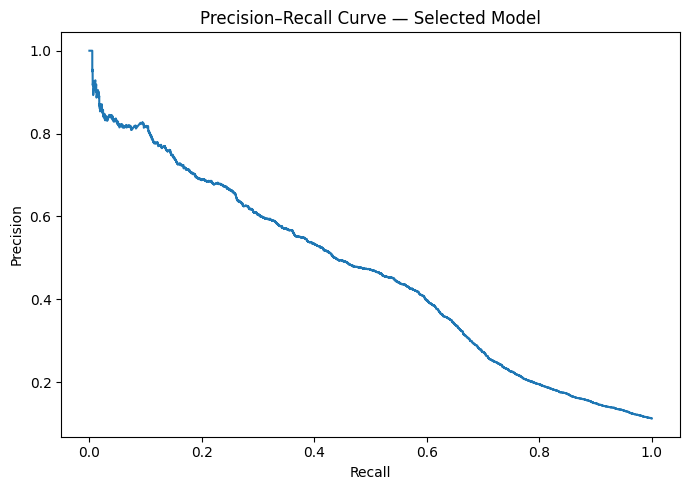

In [ ]:
# Precision–Recall Curve
from sklearn.metrics import precision_recall_curve

precision, recall, _ = precision_recall_curve(
    y_train,
    oof_proba
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall,
    precision
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "Precision–Recall Curve — Selected Model"
)

plt.tight_layout()
plt.show()

#### Threshold Analysis Interpretation

Threshold analysis menunjukkan trade-off yang jelas antara **Precision, Recall, dan jumlah client yang diprioritaskan**.

- **0.20** menghasilkan Recall sangat tinggi (**0.9679**), tetapi sekitar **88.58%** observations akan diprioritaskan. Scenario ini kurang sesuai untuk campaign prioritization karena hampir seluruh client tetap menjadi target.
- **0.40** menurunkan targeted rate menjadi **27.87%**, dengan Precision **0.2803** dan Recall **0.6934**.
- **0.50** memprioritaskan sekitar **19.75%** observations, dengan Precision **0.3592** dan Recall **0.6296**.
- **0.60** menghasilkan target yang lebih selektif sekitar **15.99%**, dengan Precision **0.4132** dan Recall **0.5865**.
- **0.70** mempersempit target menjadi **13.31%**, dengan Precision **0.4523**, Recall **0.5342**, dan F1-score tertinggi di antara tested thresholds sebesar **0.4899**.

Pada tested thresholds, semakin tinggi threshold, semakin sedikit client yang diprioritaskan dan Precision meningkat, sementara Recall menurun.

Meskipun threshold **0.70** menghasilkan F1-score tertinggi pada training OOF evaluation, hal tersebut tidak otomatis menjadikannya business-optimal threshold karena F1-score bukan standalone business objective.

Threshold **0.60** dipilih sebagai **more selective reference scenario** dibanding default threshold 0.50 karena menghasilkan target pool yang lebih kecil sambil tetap mempertahankan Recall yang relatif tinggi.

Karena campaign capacity, actual contact cost, dan financial value per subscription tidak tersedia dalam dataset, threshold tidak dapat ditetapkan sebagai financially optimal threshold.

Oleh karena itu, threshold **0.50 dan 0.60** digunakan sebagai predefined operating scenarios pada untouched test set.

### 5.6 Final Model Evaluation

Final evaluation dilakukan menggunakan **untouched test set** untuk mengukur generalization performance selected model terhadap observations yang tidak digunakan selama model development.

Selected model adalah **Base Gradient Boosting + Random Oversampling**, karena menghasilkan 5-fold CV AP sedikit lebih tinggi dibanding tuned configuration.

Evaluation mencakup:

- **ROC-AUC dan Average Precision (AP)** sebagai threshold-independent metrics.
- **Precision, Recall, F1-score, Accuracy, dan targeted rate** pada dua predefined operating scenarios:
  - threshold **0.50** sebagai default threshold;
  - threshold **0.60** sebagai more selective scenario dari training OOF threshold analysis.

Threshold comparison pada test set digunakan untuk **reporting generalization performance**, bukan untuk mencari financially optimal threshold.

In [ ]:
# 1. Fit + probabilities + ranking metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

selected_model.fit(
    X_train,
    y_train
)

test_proba = selected_model.predict_proba(
    X_test
)[:, 1]

test_roc_auc = roc_auc_score(
    y_test,
    test_proba
)

test_ap = average_precision_score(
    y_test,
    test_proba
)

print(
    f"Test ROC-AUC : {test_roc_auc:.4f}"
)

print(
    f"Test AP  : {test_ap:.4f}"
)

Test ROC-AUC : 0.8140
Test AP  : 0.4810


In [ ]:
# 2. threshold comparison

final_thresholds = [
    0.50,
    0.60
]

final_results = []

for threshold in final_thresholds:

    y_pred = (
        test_proba >= threshold
    ).astype(int)

    targeted_clients = y_pred.sum()

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        y_pred
    ).ravel()

    final_results.append({
        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_test,
            y_pred
        ),

        "Precision": precision_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_test,
            y_pred,
            zero_division=0
        ),

        "Targeted Clients":
            targeted_clients,

        "Targeted Rate (%)":
            targeted_clients
            / len(y_test)
            * 100,

        "TP": tp,
        "FP": fp,
        "FN": fn,
        "TN": tn
    })

final_evaluation_df = pd.DataFrame(
    final_results
)

display(
    final_evaluation_df.round(4)
)

,Threshold,Accuracy,Precision,Recall,F1-score,Targeted Clients,Targeted Rate (%),TP,FP,FN,TN
0,0.5,0.8410,0.3811,0.6595,0.4830,1606,19.4950,612,994,316,6316
1,0.6,0.8678,0.4381,0.6142,0.5114,1301,15.7927,570,731,358,6579


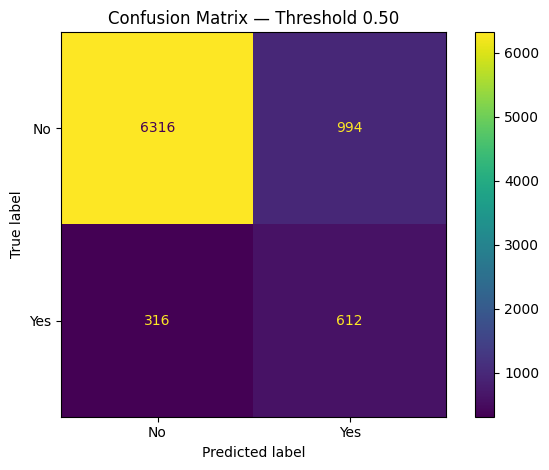

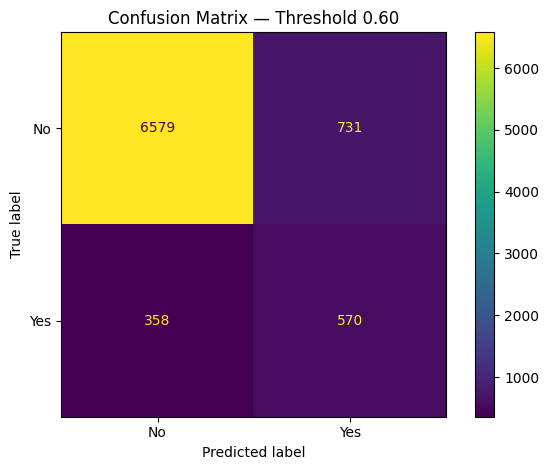

In [ ]:
# Confusion Matrix
for threshold in final_thresholds:

    y_pred = (
        test_proba >= threshold
    ).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        display_labels=[
            "No",
            "Yes"
        ],
        values_format="d"
    )

    plt.title(
        f"Confusion Matrix — Threshold {threshold:.2f}"
    )

    plt.tight_layout()
    plt.show()

#### Confusion-Matrix Business Impact

Confusion Matrix digunakan untuk menerjemahkan classification error ke dalam business consequence.

Dua error yang menjadi perhatian utama adalah:

- **False Positive (FP)** — client diprioritaskan dan dihubungi tetapi tidak melakukan subscription. Dengan asumsi satu benchmark-equivalent outbound contact per prioritized client, FP merepresentasikan potential unnecessary contact cost.
- **False Negative (FN)** — client tidak diprioritaskan padahal sebenarnya melakukan subscription. FN merepresentasikan missed subscriber opportunity.

FP dapat dikonversi ke illustrative contact cost menggunakan benchmark pada Section 1.5.

Sebaliknya, FN tidak dikonversi ke monetary value karena dataset tidak menyediakan revenue per subscription, deposit value, profit margin, maupun customer lifetime value.

In [ ]:
# Confusion-matrix business impact

cost_scenarios = [
    5.00,
    9.10
]

error_impact_results = []

for _, row in final_evaluation_df.iterrows():

    for contact_cost in cost_scenarios:

        error_impact_results.append({
            "Threshold":
                row["Threshold"],

            "TP":
                int(row["TP"]),

            "FP":
                int(row["FP"]),

            "FN":
                int(row["FN"]),

            "Cost per Contact (USD)":
                contact_cost,

            "Illustrative FP Contact Cost (USD)":
                row["FP"] * contact_cost,

            "FN Missed Subscribers":
                int(row["FN"])
        })

error_impact_df = pd.DataFrame(
    error_impact_results
)

display(
    error_impact_df.round(2)
)

,Threshold,TP,FP,FN,Cost per Contact (USD),Illustrative FP Contact Cost (USD),FN Missed Subscribers
0,0.5,612,994,316,5.0,4970.0,316
1,0.5,612,994,316,9.1,9045.4,316
2,0.6,570,731,358,5.0,3655.0,358
3,0.6,570,731,358,9.1,6652.1,358


#### Final Evaluation Interpretation

Selected model menghasilkan **ROC-AUC 0.8140** dan **Average Precision (AP) 0.4810** pada untouched test set.

AP pada test set sejalan dengan 5-fold CV AP sebelumnya (**0.4634**), menunjukkan ranking performance yang relatif konsisten dengan cross-validation.

| Threshold | Precision | Recall | F1-score | Targeted Clients | TP | FP | FN |
|---:|---:|---:|---:|---:|---:|---:|---:|
| **0.50** | 0.3811 | **0.6595** | 0.4830 | 1,606 (19.50%) | **612** | 994 | **316** |
| **0.60** | **0.4381** | 0.6142 | **0.5114** | 1,301 (15.79%) | 570 | **731** | 358 |

Threshold **0.50** memberikan subscriber coverage yang lebih tinggi, sedangkan threshold **0.60** menghasilkan target pool yang lebih selective dengan Precision dan F1-score yang lebih tinggi.

##### Business Impact Interpretation

Berdasarkan illustrative contact-cost scenarios:

| Threshold | FP | FP Cost @ USD 5.00 | FP Cost @ USD 9.10 | FN |
|---:|---:|---:|---:|---:|
| **0.50** | 994 | USD 4,970 | USD 9,045.40 | 316 |
| **0.60** | 731 | USD 3,655 | USD 6,652.10 | 358 |

Dibanding threshold 0.50, threshold **0.60 mengurangi 263 False Positives**, sehingga potential unnecessary contact cost berkurang sekitar:

- **USD 1,315** pada scenario USD 5.00/contact;
- **USD 2,393.30** pada scenario USD 9.10/contact.

Trade-off-nya adalah False Negative meningkat dari **316 menjadi 358**, atau terdapat **42 additional actual subscribers yang tidak memperoleh campaign priority**.

Dengan demikian:

- threshold **0.50** lebih sesuai ketika **subscriber coverage** menjadi prioritas;
- threshold **0.60** lebih sesuai ketika **campaign capacity lebih terbatas dan targeting efficiency** menjadi prioritas.

Kedua threshold merupakan **operating scenarios**, bukan financially optimal thresholds.

### 5.7 Model Interpretation

#### Selected Model: Gradient Boosting + Random Oversampling

Selected model adalah **Base Gradient Boosting + Random Oversampling**.

Model ini dipilih berdasarkan **5-fold cross-validation Average Precision (AP)** karena menghasilkan AP tertinggi di antara evaluated imbalance-treatment configurations, yaitu **0.4634**.

Hyperparameter tuning tidak meningkatkan primary metric:

- Base Gradient Boosting + Random Oversampling: **AP 0.4634**
- Tuned Gradient Boosting + Random Oversampling: **AP 0.4625**

Karena improvement tidak diperoleh dari tuning, base configuration dipertahankan sebagai selected model dengan performance sedikit lebih baik dan configuration yang lebih sederhana.

#### How the Selected Model Works

Selected model menggabungkan **Gradient Boosting** sebagai classifier dan **Random Oversampling** sebagai treatment terhadap class imbalance.

##### Gradient Boosting

Gradient Boosting membangun kumpulan decision trees secara **sequential**.

Secara sederhana:

1. tree pertama membuat initial prediction;
2. tree berikutnya mempelajari errors yang masih belum dapat dijelaskan dengan baik;
3. setiap tree baru memberikan correction terhadap prediction sebelumnya;
4. final prediction merupakan kombinasi contribution dari seluruh trees.

Pendekatan ini memungkinkan model menangkap **non-linear relationships dan interaction antar features**, yang relevan karena predictive patterns pada dataset melibatkan kombinasi client profile, campaign context, previous campaign history, dan economic indicators.

##### Random Oversampling

Dataset memiliki positive class (`y = yes`) hanya sekitar **11.27%**, sehingga training data didominasi oleh non-subscriber.

Random Oversampling meningkatkan representation minority class pada **training folds** dengan melakukan sampling ulang observations dari positive class.

Metode ini:

- tidak mengubah test set;
- tidak diterapkan sebelum train-test split;
- tidak membuat synthetic observations baru;
- hanya meningkatkan exposure model terhadap minority class selama training.

Oversampling ditempatkan di dalam modeling pipeline sehingga treatment hanya dilakukan pada training portion di setiap cross-validation fold dan tidak menyebabkan data leakage.

##### Combined Modeling Logic

Selected pipeline memiliki flow yang berbeda antara **training** dan **scoring**.

**Training**

**Raw Training Data → Random Oversampling → Feature Engineering → Preprocessing → Gradient Boosting**

Random Oversampling diterapkan hanya pada training data untuk meningkatkan representation minority class. Setelah resampling, data melewati feature engineering dan preprocessing yang sama sebelum digunakan untuk melatih Gradient Boosting.

**Scoring**

**Eligible Client Data → Feature Engineering → Preprocessing → Gradient Boosting → Prediction Score**

Pada scoring, Random Oversampling tidak digunakan. Model menghasilkan **prediction score** yang digunakan untuk client ranking dan campaign prioritization.

#### Permutation Importance

Permutation Importance digunakan untuk memahami feature yang paling informatif bagi prediction model.

Metode ini mengukur penurunan model performance ketika nilai suatu feature diacak sementara feature lainnya tetap dipertahankan.

Importance dihitung pada **test set** menggunakan **Average Precision (AP)** sebagai scoring metric, konsisten dengan primary evaluation metric project.

Karena permutation dilakukan pada original input features sebelum preprocessing pipeline, hasil importance tetap dapat dikaitkan langsung dengan business features.

Permutation Importance menunjukkan **predictive contribution terhadap model**, bukan causal effect terhadap subscription.

In [ ]:
# Permutation Importance
from sklearn.inspection import permutation_importance

perm_importance = permutation_importance(
    selected_model,
    X_test,
    y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

feature_importance_df = (
    pd.DataFrame({
        "Feature": X_test.columns,
        "Importance Mean":
            perm_importance.importances_mean,
        "Importance Std":
            perm_importance.importances_std
    })
    .sort_values(
        "Importance Mean",
        ascending=False
    )
    .reset_index(drop=True)
)

top_features = feature_importance_df.head(10)

display(
    top_features.round(4)
)

,Feature,Importance Mean,Importance Std
0,nr.employed,0.1568,0.0096
1,euribor3m,0.0426,0.0032
2,pdays,0.0382,0.0059
3,emp.var.rate,0.0159,0.0023
4,contact,0.0138,0.0010
5,campaign,0.0135,0.0013
6,poutcome,0.0122,0.0025
7,cons.conf.idx,0.0091,0.0018
8,day_of_week,0.0062,0.0026
9,cons.price.idx,0.0054,0.0014


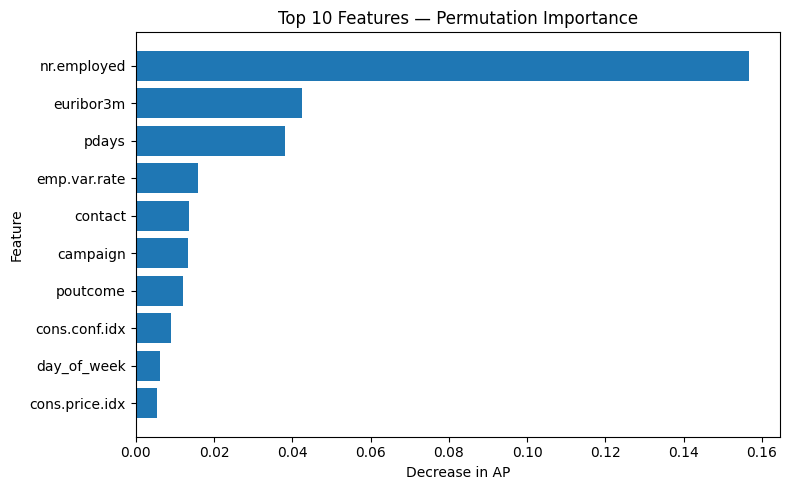

In [ ]:
# plot
plot_features = (
    top_features
    .sort_values("Importance Mean")
)

plt.figure(figsize=(8, 5))

plt.barh(
    plot_features["Feature"],
    plot_features["Importance Mean"]
)

plt.xlabel("Decrease in AP")
plt.ylabel("Feature")
plt.title(
    "Top 10 Features — Permutation Importance"
)

plt.tight_layout()
plt.show()

#### Permutation Importance Result

Permutation Importance menunjukkan bahwa selected model terutama menggunakan informasi dari **economic conditions, previous contact history, dan campaign context**.

Feature dengan predictive contribution terbesar adalah:

- **`nr.employed` — 0.1568**, substantially lebih tinggi dibanding feature lainnya.
- **`euribor3m` — 0.0426**.
- **`pdays` — 0.0382**.
- **`emp.var.rate` — 0.0159**.
- **`contact` — 0.0138**.
- **`campaign` — 0.0135**.
- **`poutcome` — 0.0122**.

Economic indicators seperti `nr.employed`, `euribor3m`, dan `emp.var.rate` memberikan predictive information yang cukup besar. Previous-contact information (`pdays`, `poutcome`) dan campaign context (`contact`, `campaign`) juga berkontribusi terhadap prediction.

Interpretation perlu dilakukan dengan hati-hati karena beberapa economic features saling berkorelasi. Ketika correlated features membawa overlapping information, Permutation Importance dapat membagi atau mengurangi apparent importance masing-masing feature.

`pdays` pada hasil Permutation Importance merupakan **original input feature**. Di dalam pipeline, feature tersebut kemudian ditransformasikan menjadi `pdays_clean` dan `previously_contacted`. Oleh karena itu, importance `pdays` merepresentasikan predictive information yang berasal dari previous-contact history tersebut.

Permutation Importance menunjukkan **predictive contribution terhadap model performance**, bukan causal relationship terhadap subscription.

#### SHAP Analysis

SHAP digunakan untuk menjelaskan bagaimana transformed feature values berkontribusi terhadap model output.

Berbeda dengan Permutation Importance yang mengukur perubahan model performance ketika suatu original feature diacak, SHAP menjelaskan **direction dan magnitude contribution dari setiap transformed feature**.

Interpretation:

- **positive SHAP value** mendorong model output ke arah subscription (`y = 1`);
- **negative SHAP value** mendorong model output menjauh dari subscription;
- semakin besar absolute SHAP value, semakin besar contribution feature terhadap model output.

Untuk computational efficiency, SHAP dihitung pada reproducible sample maksimal **1,000 observations dari test set** (`random_state=42`).

SHAP digunakan sebagai **model explanation**, bukan sebagai bukti causal relationship.

In [ ]:
# SHAP preparation

import shap
from scipy import sparse

# Use a sample to keep SHAP computation efficient
X_shap_raw = X_test.sample(
    n=min(1000, len(X_test)),
    random_state=42
)

feature_engineering_step = (
    selected_model.named_steps[
        "feature_engineering"
    ]
)

preprocessor_step = (
    selected_model.named_steps[
        "preprocessor"
    ]
)

model_step = (
    selected_model.named_steps[
        "model"
    ]
)

# Apply the same transformation used by the model
X_shap_fe = (
    feature_engineering_step
    .transform(X_shap_raw)
)

X_shap_transformed = (
    preprocessor_step
    .transform(X_shap_fe)
)

# Convert sparse matrix if needed
if sparse.issparse(
    X_shap_transformed
):
    X_shap_transformed = (
        X_shap_transformed
        .toarray()
    )

# Get transformed feature names
feature_names = (
    preprocessor_step
    .get_feature_names_out()
)

X_shap_df = pd.DataFrame(
    X_shap_transformed,
    columns=feature_names,
    index=X_shap_raw.index
)

print(
    "SHAP sample shape:",
    X_shap_df.shape
)

SHAP sample shape: (1000, 45)


In [ ]:
# SHAP values

explainer = shap.TreeExplainer(
    model_step
)

shap_values = explainer(
    X_shap_df
)

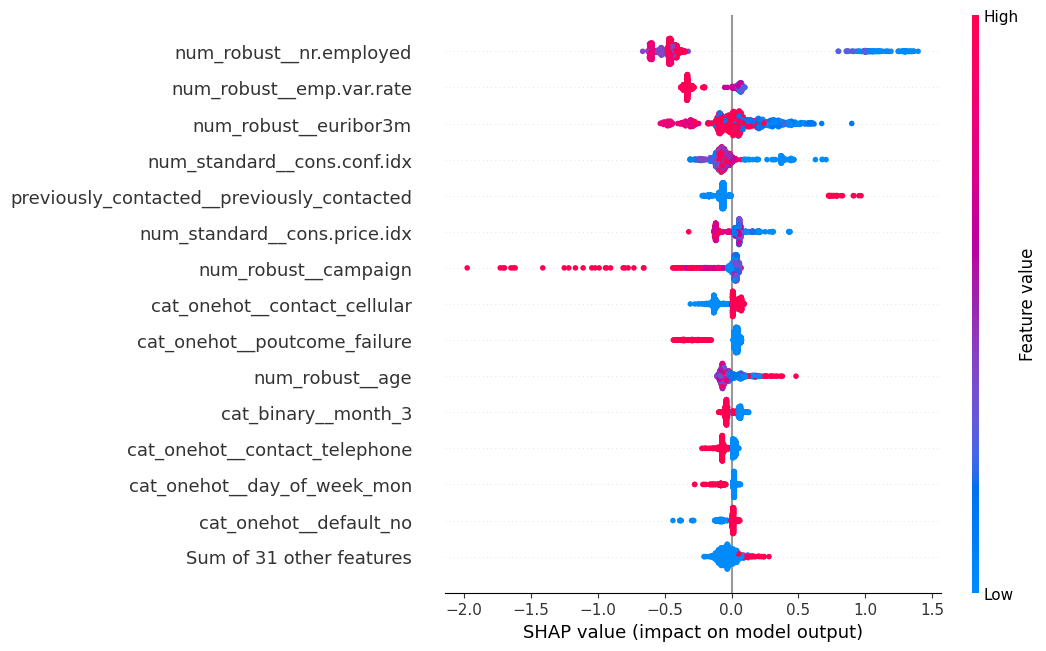

In [ ]:
# SHAP beeswarm plot

shap.plots.beeswarm(
    shap_values,
    max_display=15
)

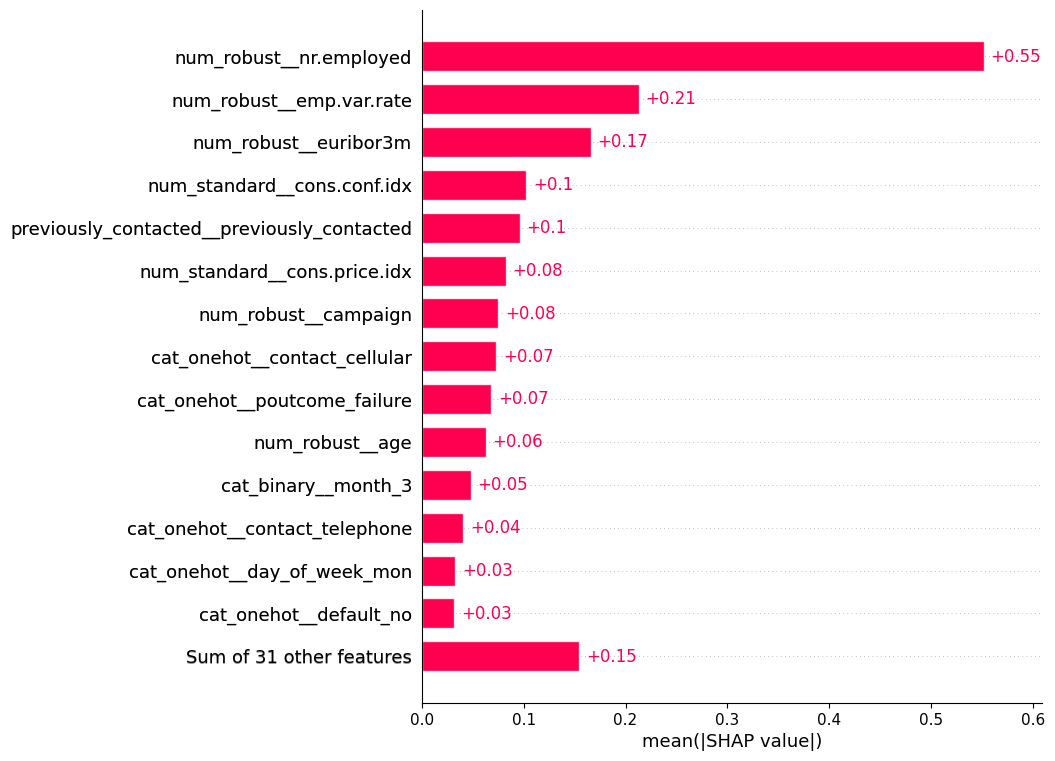

In [ ]:
# SHAP global importance

shap.plots.bar(
    shap_values,
    max_display=15
)

#### SHAP Interpretation

Berdasarkan mean absolute SHAP value, transformed features dengan global contribution terbesar adalah:

- `nr.employed` — sekitar **0.55**
- `emp.var.rate` — sekitar **0.21**
- `euribor3m` — sekitar **0.17**
- `cons.conf.idx` — sekitar **0.10**
- `previously_contacted` — sekitar **0.10**

Beeswarm plot menunjukkan beberapa patterns utama:

- **Lower `nr.employed` values** cenderung memberikan positive contribution terhadap model output, sedangkan higher values cenderung memberikan negative contribution.
- **Lower `emp.var.rate` dan `euribor3m` values** juga cenderung mendorong model output ke arah subscription.
- Client yang **previously contacted** cenderung memperoleh positive contribution terhadap prediction.
- **Higher `campaign` values** cenderung memberikan negative contribution terhadap model output.
- `contact = cellular` cenderung memberikan positive contribution, sedangkan `contact = telephone` cenderung memberikan negative contribution.
- `poutcome = failure` cenderung memberikan negative contribution terhadap model output.

Beberapa categorical features telah melalui One Hot Encoding atau Binary Encoding. Oleh karena itu, transformed features seperti `cat_binary__month_3` merupakan **encoded component** dan tidak merepresentasikan satu business category secara langsung. Business interpretation untuk feature tersebut tetap mengacu pada original feature analysis pada EDA.

SHAP menjelaskan **bagaimana model menggunakan feature values untuk menghasilkan prediction**, bukan causal effect. Positive atau negative SHAP value tidak berarti bahwa perubahan suatu feature secara langsung akan menyebabkan perubahan subscription outcome.

#### Model Interpretation Summary

Permutation Importance dan SHAP menggunakan definition of importance yang berbeda, sehingga magnitude keduanya tidak dapat dibandingkan secara langsung.

Namun, kedua methods secara konsisten menunjukkan bahwa **economic indicators merupakan major predictive signals dalam selected model**, sementara previous-contact history dan campaign context memberikan additional predictive information.

## 6. Conclusion and Recommendation

### 6.1 Key Business & Analytics Insights

Analisis menghasilkan beberapa findings utama yang relevan terhadap campaign prioritization.

| Business Insight | Evidence | Business Interpretation |
|---|---|---|
| **Previous campaign response merupakan historical signal yang kuat** | `poutcome = success` memiliki subscription rate sekitar **65.11%**, dibanding overall rate **11.27%**. `poutcome` juga memiliki Cramer's V sekitar **0.320**. | Historical campaign response dapat digunakan sebagai salah satu signal untuk mengidentifikasi client dengan historical subscription tendency yang lebih tinggi. |
| **Higher contact frequency tidak diikuti historical subscription rate yang lebih tinggi** | Subscription rate menurun dari sekitar **13.04% pada 1 contact** menjadi **3.11% pada >10 contacts**. | Repeated contact perlu dimonitor bersama client response history dan prediction score. Pattern ini bersifat observational dan tidak menunjukkan causal effect. |
| **Campaign context menunjukkan substantial variation** | Cellular memiliki subscription rate **14.74%** dibanding telephone **5.23%**. Subscription rate juga berbeda antar campaign month. | Channel dan timing merupakan contextual signals, tetapi tidak dapat digunakan sebagai standalone causal targeting rules. |
| **Economic conditions membawa predictive information yang penting** | `nr.employed`, `euribor3m`, dan `emp.var.rate` menunjukkan association dengan target dan termasuk features dengan permutation importance yang relatif tinggi. | Campaign performance dan model behavior dapat berubah ketika economic conditions berubah. |
| **Predictive prioritization dapat mempersempit target campaign** | Pada untouched test set, model menghasilkan **AP 0.4810**. Threshold **0.60** memprioritaskan **1,301 dari 8,238 clients (15.79%)**, dengan Precision **43.81%** dan Recall **61.42%**. | Prediction score dapat digunakan sebagai ranking mechanism untuk membantu menentukan campaign priority berdasarkan operational capacity. |

Client demographic characteristics tetap memberikan **contextual information**, tetapi tidak cukup kuat untuk digunakan sebagai standalone targeting rules.

Secara keseluruhan, campaign prioritization sebaiknya tidak bergantung pada satu customer characteristic atau satu campaign variable. Evidence menunjukkan bahwa **historical response, campaign context, economic conditions, dan prediction score** memberikan informasi yang saling melengkapi.

Seluruh findings merupakan **associational and predictive evidence**, bukan causal conclusions.

### 6.2 Machine Learning Conclusion

Machine Learning digunakan untuk menghasilkan **prediction score** sehingga Marketing / Campaign Manager dapat melakukan client ranking dan campaign prioritization.

Karena positive class hanya sekitar **11.27%**, **Average Precision (AP)** digunakan sebagai primary model-selection metric.

**Base Gradient Boosting + Random Oversampling** dipilih sebagai selected model dengan 5-fold CV AP **0.4634**. Hyperparameter tuning tidak memberikan improvement dibanding base configuration (**0.4625**).

Pada untouched test set, selected model menghasilkan:

- **ROC-AUC: 0.8140**
- **AP: 0.4810**

Operating threshold menunjukkan trade-off antara coverage dan efficiency:

- threshold **0.50** memberikan Recall **65.95%** dan menargetkan **19.50%** clients;
- threshold **0.60** memberikan Precision **43.81%**, Recall **61.42%**, dan menargetkan **15.79%** clients.

Dengan demikian, selected model dapat digunakan sebagai **decision-support tool untuk client ranking dan campaign prioritization**, sedangkan final threshold ditentukan berdasarkan campaign capacity dan business priorities.

### 6.3 Business Recommendations

Recommendations berikut diturunkan dari analytical findings dan model performance. Model digunakan sebagai **decision-support tool**, bukan sebagai standalone decision rule.

| Priority | Recommended Action | Owner | Execution / Trigger | KPI |
|---|---|---|---|---|
| **1** | **Prioritize clients using prediction score** | Marketing / Campaign Manager | Score eligible clients sebelum contact attempt, rank berdasarkan prediction score, lalu pilih target sesuai campaign capacity. | Recall, Precision, Targeted Rate, Subscription Rate |
| **2** | **Use previous campaign response as supporting context** | Marketing / Campaign Manager, CRM Team | Gunakan `poutcome` dan previous-contact history untuk membantu segmentation dan interpretation. Gunakan sebagai supporting signal, bukan standalone targeting rule, karena informasi tersebut sudah termasuk dalam model. | Subscription Rate by `poutcome`, Recall |
| **3** | **Review clients with repeated contact attempts** | Campaign Manager, Contact Center | Flag clients dengan current-campaign contact count yang semakin tinggi dan review prediction score serta previous response sebelum additional contact dilakukan. Higher contact frequency digunakan sebagai review trigger, bukan automatic stop rule. | Average Contacts per Client, Subscription Rate by Contact Count |
| **4** | **Consider economic context when interpreting campaign performance** | Marketing / Campaign Manager, Model Owner | Track `nr.employed`, `euribor3m`, dan `emp.var.rate` ketika membandingkan campaign performance antar periods. Lakukan model re-evaluation jika feature distributions atau predictive performance berubah secara meaningful. | AP, Recall, Feature Distribution |

#### Recommended Operating Scenarios

Berdasarkan final test-set evaluation:

| Scenario | Threshold | Targeted Clients | Precision | Recall | Recommended Use |
|---|---:|---:|---:|---:|---|
| **Coverage-oriented** | **0.50** | 1,606 (19.50%) | 38.11% | **65.95%** | Ketika campaign memiliki capacity yang lebih besar dan subscriber coverage menjadi prioritas |
| **Efficiency-oriented** | **0.60** | 1,301 (15.79%) | **43.81%** | 61.42% | Ketika campaign capacity lebih terbatas dan target pool perlu lebih selective |

Threshold **0.50 dan 0.60 merupakan operating scenarios, bukan financially optimal thresholds**. Final cut-off perlu disesuaikan dengan actual campaign capacity, business eligibility rules, dan observed campaign performance.

#### Recommended Campaign Workflow

**Eligible Clients → Generate Prediction Score → Rank Clients → Apply Campaign Capacity / Threshold → Contact Prioritized Clients → Record Outcome → Evaluate Campaign Performance**

Prediction score digunakan untuk menentukan **priority order**, sedangkan final campaign decision tetap mempertimbangkan operational capacity dan business rules.